# UTS Praktikum Visi Komputer
## Tema 9 — Pengenalan Kartu Remi

Program mengenali kartu remi pada foto (misalnya "7 Hati") dengan **mencocokkan fitur ORB/SIFT terhadap 12 template**, termasuk saat kartu diputar, diperkecil, atau difoto miring.

**Alur:** foto → resize → grayscale → blur → segmentasi → kontur 4 sudut → warp tegak → fitur ORB/SIFT → knn match + ratio test ke 12 template → nama kartu dan jumlah good match.

## 1. Identitas

| | |
|---|---|
| **Nomor kelompok** | 9 |
| **Tema** | 9 — Pengenalan Kartu Remi |

| Nama | NIM |
|---|---|
| Muhammad Yazid Arrazi | 2408107010072 |
| Muhammad Farhan Alafif | 2408107010075 |
| Muhammad Razi Siregar | 2408107010101 |

### Sumber kode

| Bagian kode | Sumber |
|---|---|
| `imread`, `cvtColor`, `imwrite`, tampil banyak gambar (`fig.add_subplot`) | Modul Prak 2 |
| `GaussianBlur` 7x7, `threshold` + `THRESH_OTSU`, `adaptiveThreshold`, `equalizeHist`, `calcHist`, konversi HSV, `resize` (`INTER_AREA`), `getRotationMatrix2D` + `warpAffine`, `flip` | Modul Prak 3 |
| `detectAndDescribe`, `createMatcher`, `matchKeyPointsKNN` (ratio test), `getHomography` (RANSAC), `drawMatches`, `warpPerspective`, `findContours` + `max(..., key=cv2.contourArea)` + `boundingRect` | Modul Prak 5 (notebook "Modul ke-5") |
| `convexHull`, `arcLength`, `approxPolyDP`, `minAreaRect`, `Canny` | Materi Prak 4 (tidak ada di notebook yang dilampirkan; ditulis mengikuti dokumentasi OpenCV) |
| Urutan 4 sudut, pemilihan kandidat kartu, loop evaluasi, tabel hasil, struktur notebook | Dibuat dengan bantuan Claude (Anthropic); kelompok sudah memeriksa dan memahami alurnya |

Perubahan kecil pada kode modul: `cv2.xfeatures2d.SIFT_create()` diganti `cv2.SIFT_create(nfeatures=1000)` (OpenCV baru; jumlah keypoint dibatasi supaya waktu proses wajar), `print` di `matchKeyPointsKNN` dihapus supaya tidak membanjiri output, `imutils.grab_contours` diganti satu baris setara karena library yang diizinkan hanya opencv-python, numpy, dan matplotlib.

### Struktur folder (dijalankan dari folder yang berisi `dataset/`)
```
UTS_VisKom_Kelompok9/
  UTS_Kelompok9.ipynb
  dataset/
    template/    3_hati.jpeg, 7_sekop.jpeg, ... (12 file)
    rotasi/ skala/ cahaya/ sulit/
    ground_truth.csv
  output/        (dibuat otomatis)
```

## 2. Import, parameter, dan fungsi bantu

Semua parameter ada di satu sel supaya mudah diubah dan dijelaskan. Setiap tahap pipeline ditulis sebagai fungsi (Prak 1).

In [1]:
import os
import csv
import time
from collections import OrderedDict, defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt

cv2.ocl.setUseOpenCL(False)      # sama seperti modul Prak 5

# ===================== LOKASI DATASET =====================
# Utama: path relatif dataset/ (syarat pengumpulan). Cadangan: Kaggle (/kaggle/input/...).
def cari_dataset():
    if os.path.isdir(os.path.join('dataset', 'template')):
        return 'dataset'
    for akar, dirs, _ in os.walk('/kaggle/input'):
        if 'template' in dirs:
            return akar
    return 'dataset'


def cari_ground_truth(dataset_dir):
    for d in (dataset_dir, os.path.dirname(os.path.normpath(dataset_dir)), '.'):
        p = os.path.join(d, 'ground_truth.csv')
        if os.path.isfile(p):
            return p
    for akar, _, files in os.walk('/kaggle/input'):
        if 'ground_truth.csv' in files:
            return os.path.join(akar, 'ground_truth.csv')
    return os.path.join(dataset_dir, 'ground_truth.csv')


DATASET_DIR = cari_dataset()
TEMPLATE_DIR = os.path.join(DATASET_DIR, 'template')
GT_PATH = cari_ground_truth(DATASET_DIR)
OUTPUT_DIR = 'output'

# ===================== PARAMETER (ubah di sini) =====================
SISI_MAKS = 1000               # sisi terpanjang foto setelah resize (soal: 800-1200 px)
UKURAN_KARTU = (300, 420)      # (lebar, tinggi) hasil warp; kartu poker 63x88 mm -> rasio 1,4

BLUR_K = (7, 7)                # kernel Gaussian blur (nilai di modul Prak 3)
CANNY = (40, 120)              # ambang bawah/atas Canny (rasio 1:3)
ADAPT_BLOK, ADAPT_C = 201, -8  # adaptive threshold: blok > ukuran kartu; C negatif = ambil yang lebih terang dari rata-rata lokal
STRATEGI = ('otsu', 'adaptif', 'canny')   # strategi segmentasi; kandidat dari semuanya digabung
MIN_AREA, MAX_AREA = 0.01, 0.60           # luas kartu / luas foto
EPS_LIST = (0.02, 0.03, 0.04, 0.05, 0.06) # epsilon approxPolyDP (x keliling), dicoba bertahap
RASIO_KARTU = 1.4              # tinggi/lebar kartu poker
MAKS_KANDIDAT = 3              # maksimum kandidat kartu per foto
SUDUT_TOL = 25                 # toleransi penyimpangan sudut segi empat dari 90 derajat (pantulan lampu membuat segi empat miring)
RASIO_LUAS_MIN = 0.35          # kandidat lebih kecil dari 35% kandidat terbesar dibuang (bayangan/noise)
MAX_AREA_TEMPLATE = 0.50       # template: kartu tidak mungkin memenuhi seluruh foto (mencegah seluruh frame dianggap kartu)

SIFT_NFEATURES = 1000          # batas keypoint SIFT per citra (default tanpa batas: ribuan keypoint, sangat lambat)
RASIO = 0.75                   # ratio test Lowe (modul Prak 5 memakai 0,75)
RANSAC_THR = 4                 # reprojThresh findHomography (modul Prak 5 memakai 4)
ORIENTASI = (0, 180)           # sudut putar yang dicoba pada kartu hasil warp (Prak 3)
PAKAI_EQ = True                # histogram equalization sebelum ekstraksi fitur (Prak 3)
SKOR_MODE = 'good'             # 'good' = jumlah good match; 'inlier' = good match yang lolos RANSAC
# skor minimum agar kartu dianggap dikenali, per mode skor dan per detektor (dasar: histogram skor di bagian 5).
# SIFT: pada run foto asli, kartu sungguhan >= 23 good match dan kandidat palsu <= 12, sehingga ambang 20 memisahkan keduanya.
# ORB: skor lebih kecil, ambang 10 dipertahankan.
AMBANG = {'good': {'sift': 20, 'orb': 10}, 'inlier': {'sift': 8, 'orb': 8}}
FILTER_WARNA = True            # True = batasi template ke warna yang sama (merah/hitam) lewat HSV (Prak 3); ketepatan warna dicek di bagian 6
DETEKTOR_UTAMA = 'sift'        # detektor untuk hasil utama; ubah setelah melihat bagian 6
DAFTAR_DETEKTOR = ('orb', 'sift')
KONDISI_ROTASI = ('rotasi', 'ideal')            # kondisi yang masuk tabel per sudut
KONDISI_SKALA = ('skala', 'rotasi', 'ideal')    # kondisi yang masuk tabel per jarak


# ===================== FUNGSI BANTU UMUM (Prak 1-3) =====================
def tampil_banyak(daftar, kolom=4, ukuran=(4, 4)):
    # gaya Prak 2: fig.add_subplot + plt.imshow(cv2.cvtColor(..., COLOR_BGR2RGB))
    baris = (len(daftar) + kolom - 1) // kolom
    fig = plt.figure(figsize=(ukuran[0] * kolom, ukuran[1] * baris))
    for i, (judul, im) in enumerate(daftar, 1):
        fig.add_subplot(baris, kolom, i)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        plt.title(judul, fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


def baca_citra(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Gambar tidak bisa dibaca: {path}')
    return img


def resize_maks(img, sisi_maks=SISI_MAKS):
    # cv2.resize dengan faktor skala dan interpolasi (Prak 3)
    s = sisi_maks / max(img.shape[:2])
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR
    return cv2.resize(img, None, fx=s, fy=s, interpolation=interp)


def putar(img, sudut):
    # rotasi terhadap pusat citra: getRotationMatrix2D + warpAffine (Prak 3)
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1)
    return cv2.warpAffine(img, M, (w, h))


def nama_tampil(nama):
    return nama.replace('_', ' ').title() if nama else 'tidak dikenali'


def cetak_tabel(judul, kepala, baris):
    print(judul)
    kolom = list(zip(*([kepala] + [[str(x) for x in b] for b in baris])))
    lebar = [max(len(str(x)) for x in k) for k in kolom]
    garis = '+-' + '-+-'.join('-' * w for w in lebar) + '-+'
    fmt = '| ' + ' | '.join('{:<%d}' % w for w in lebar) + ' |'
    print(garis)
    print(fmt.format(*kepala))
    print(garis)
    for b in baris:
        print(fmt.format(*[str(x) for x in b]))
    print(garis)


# ===================== KODE DARI MODUL PRAK 5 (fitur dan matching) =====================
def detectAndDescribe(image, method=None):
    """Hitung keypoint dan descriptor dengan metode tertentu (kode modul Prak 5)."""
    assert method is not None, "Tentukan metode: 'sift' atau 'orb'"
    if method == 'sift':
        descriptor = cv2.SIFT_create(nfeatures=SIFT_NFEATURES)   # di modul: cv2.xfeatures2d.SIFT_create()
    elif method == 'orb':
        descriptor = cv2.ORB_create()
    (kps, features) = descriptor.detectAndCompute(image, None)
    return (kps, features)


def createMatcher(method, crossCheck):
    "Create and return a Matcher Object (kode modul Prak 5)"
    if method == 'sift' or method == 'surf':
        bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=crossCheck)
    elif method == 'orb' or method == 'brisk':
        bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=crossCheck)
    return bf


def matchKeyPointsKNN(featuresA, featuresB, ratio, method):
    # kNN k=2 + Lowe's ratio test (kode modul Prak 5; print dihapus, ditambah pengaman len(pair) == 2)
    bf = createMatcher(method, crossCheck=False)
    rawMatches = bf.knnMatch(featuresA, featuresB, 2)
    matches = []
    for pair in rawMatches:
        if len(pair) < 2:
            continue
        m, n = pair
        if m.distance < n.distance * ratio:
            matches.append(m)
    return matches


def getHomography(kpsA, kpsB, featuresA, featuresB, matches, reprojThresh):
    # homografi RANSAC dari padanan fitur (kode modul Prak 5)
    kpsA = np.float32([kp.pt for kp in kpsA])
    kpsB = np.float32([kp.pt for kp in kpsB])
    if len(matches) > 4:
        ptsA = np.float32([kpsA[m.queryIdx] for m in matches])
        ptsB = np.float32([kpsB[m.trainIdx] for m in matches])
        (H, status) = cv2.findHomography(ptsA, ptsB, cv2.RANSAC, reprojThresh)
        return (matches, H, status)
    else:
        return None


# ===================== TAHAP 1: PRAPROSES DAN SEGMENTASI =====================
def praproses(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)     # Prak 2/3
    blur = cv2.GaussianBlur(gray, BLUR_K, 0)         # Prak 3
    return gray, blur


def segmentasi(blur, strategi):
    if strategi == 'otsu':       # Prak 3: Otsu; kartu putih -> piksel terang jadi foreground
        _, m = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
        k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
        return cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    if strategi == 'adaptif':    # Prak 3: adaptive thresholding (rata-rata Gaussian)
        m = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, ADAPT_BLOK, ADAPT_C)
        k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
        return cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    if strategi == 'canny':      # Prak 4: tepi Canny, ditebalkan lalu ditutup agar kontur tertutup
        tepi = cv2.Canny(blur, CANNY[0], CANNY[1])
        tepi = cv2.dilate(tepi, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)), iterations=1)
        return cv2.morphologyEx(tepi, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)))
    raise ValueError(f'strategi tidak dikenal: {strategi}')


def cari_kontur(mask):
    # findContours seperti di modul Prak 5; imutils.grab_contours diganti satu baris setara
    cnts = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return cnts[0] if len(cnts) == 2 else cnts[1]


# ===================== TAHAP 2: KONTUR -> 4 SUDUT KARTU (Prak 4) =====================
def kontur_ke_quad(kontur):
    hull = cv2.convexHull(kontur)
    luas_hull = cv2.contourArea(hull)
    if luas_hull <= 0:
        return None, 0
    keliling = cv2.arcLength(hull, True)
    quad = None
    for eps in EPS_LIST:                        # naikkan epsilon sampai tepat 4 titik
        approx = cv2.approxPolyDP(hull, eps * keliling, True)
        if len(approx) == 4:
            quad = approx.reshape(4, 2).astype(np.float32)
            break
    if quad is None:                            # cadangan: persegi panjang terkecil
        rect = cv2.minAreaRect(hull)
        w, h = rect[1]
        if w * h > 0 and luas_hull / (w * h) > 0.85:
            quad = cv2.boxPoints(rect).astype(np.float32)
    if quad is None:
        return None, luas_hull
    rasio_luas = luas_hull / max(cv2.contourArea(quad), 1e-6)
    if not (0.9 <= rasio_luas <= 1.15):         # bentuk hull harus mirip segi empat hasil aproksimasi
        return None, luas_hull
    return quad, luas_hull


def urutkan_titik(pts):
    # Urut searah jarum jam dari pusat, sisi PENDEK di atas (aman untuk kartu 45 derajat).
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    pusat = pts.mean(axis=0)
    sudut = np.arctan2(pts[:, 1] - pusat[1], pts[:, 0] - pusat[0])
    p = pts[np.argsort(sudut)]
    sisi = [np.linalg.norm(p[(i + 1) % 4] - p[i]) for i in range(4)]
    if sisi[0] + sisi[2] > sisi[1] + sisi[3]:
        p = np.roll(p, -1, axis=0)
    return p


def ukuran_quad(p):
    lebar = (np.linalg.norm(p[1] - p[0]) + np.linalg.norm(p[2] - p[3])) / 2
    tinggi = (np.linalg.norm(p[3] - p[0]) + np.linalg.norm(p[2] - p[1])) / 2
    return lebar, tinggi


def selisih_sudut(p):
    # Penyimpangan terbesar sudut segi empat dari 90 derajat. Kartu asli hampir persegi panjang,
    # sedangkan kontur yang menyatu dengan pantulan lampu menjadi jajar genjang miring.
    dev = 0.0
    for i in range(4):
        a, b = p[i - 1] - p[i], p[(i + 1) % 4] - p[i]
        cosv = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9)
        dev = max(dev, abs(np.degrees(np.arccos(np.clip(cosv, -1, 1))) - 90))
    return dev


# ===================== TAHAP 3: PELURUSAN (warpPerspective, Prak 5) =====================
def luruskan(img, quad, ukuran=UKURAN_KARTU, asli=None):
    # img = citra kerja (hasil resize, tempat kartu dideteksi). asli = foto resolusi penuh (opsional):
    # kalau ada, kartu di-warp dari foto asli supaya tajam (kartu kecil di foto 1000 px akan buram bila diperbesar).
    p = urutkan_titik(quad)
    sumber, titik = img, p
    if asli is not None:
        f = asli.shape[1] / img.shape[1]
        sumber, titik = asli, p * f
    W, H = ukuran
    W2, H2 = 2 * W, 2 * H                       # warp di 2x ukuran lalu diperkecil (INTER_AREA, Prak 3) agar tajam
    dst = np.float32([[0, 0], [W2 - 1, 0], [W2 - 1, H2 - 1], [0, H2 - 1]])
    M, _ = cv2.findHomography(titik, dst)       # 4 pasang titik -> homografi tepat
    warp = cv2.warpPerspective(sumber, M, (W2, H2))
    return cv2.resize(warp, (W, H), interpolation=cv2.INTER_AREA), p


def deteksi_kartu(img, maks_kartu=MAKS_KANDIDAT, min_area=MIN_AREA, max_area=MAX_AREA, asli=None):
    _, blur = praproses(img)
    area_img = img.shape[0] * img.shape[1]
    kandidat = []
    mask_otsu = None
    for s in STRATEGI:
        mask = segmentasi(blur, s)
        if s == 'otsu':
            mask_otsu = mask
        for c in cari_kontur(mask):
            x, y, bw, bh = cv2.boundingRect(c)
            if bw * bh < 0.5 * min_area * area_img:     # saring cepat: terlalu kecil
                continue
            quad, luas = kontur_ke_quad(c)
            if quad is None or not (min_area <= luas / area_img <= max_area):
                continue
            p = urutkan_titik(quad)
            w, h = ukuran_quad(p)
            if w < 1:
                continue
            # utamakan luas besar, rasio mirip kartu (1,4), dan sudut mendekati 90 derajat
            nilai = (luas * np.exp(-(((h / w) - RASIO_KARTU) / 0.3) ** 2)
                     * np.exp(-(selisih_sudut(p) / SUDUT_TOL) ** 2))
            kandidat.append((nilai, luas, p, s))
    kandidat.sort(key=lambda x: -x[0])
    if kandidat:                                        # buang kandidat kecil (bayangan/noise) dibanding yang terbesar
        luas_maks = max(k[1] for k in kandidat[:maks_kartu + 2])
        kandidat = [k for k in kandidat if k[1] >= RASIO_LUAS_MIN * luas_maks or k is kandidat[0]]
    terpilih = []
    for nilai, luas, p, s in kandidat:                  # buang kandidat kembar antar-strategi
        pusat = p.mean(axis=0)
        kembar = any(np.linalg.norm(pusat - t['quad'].mean(axis=0)) < 0.5 * np.sqrt(min(luas, t['luas']))
                     for t in terpilih)
        if not kembar:
            warp, p2 = luruskan(img, p, asli=asli)
            terpilih.append(dict(quad=p2, luas=luas, strategi=s, warp=warp, cadangan=False, cache={}))
        if len(terpilih) >= maks_kartu:
            break
    if not terpilih and mask_otsu is not None:          # cadangan: ROI boundingRect kontur terbesar (modul Prak 5)
        cnts = cari_kontur(mask_otsu)
        if cnts:
            c = max(cnts, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            sumber, f = (img, 1.0) if asli is None else (asli, asli.shape[1] / img.shape[1])
            roi = sumber[int(y * f):int((y + h) * f), int(x * f):int((x + w) * f)]
            if roi.size > 0 and w * h >= min_area * area_img:
                if w > h:                                # buat tegak
                    roi = cv2.rotate(roi, cv2.ROTATE_90_CLOCKWISE)
                roi = cv2.resize(roi, UKURAN_KARTU, interpolation=cv2.INTER_AREA)
                quad = np.float32([[x, y], [x + w, y], [x + w, y + h], [x, y + h]])
                terpilih.append(dict(quad=quad, luas=w * h, strategi='cadangan', warp=roi,
                                     cadangan=True, cache={}))
    return terpilih


def normalisasi_template(img, asli=None):
    # Template idealnya sudah di-crop. Kalau masih ada latar, kartu dicari dan diluruskan otomatis.
    # max_area dibatasi: seluruh frame foto tidak boleh dianggap sebagai kartu.
    kand = deteksi_kartu(img, maks_kartu=1, min_area=0.005, max_area=MAX_AREA_TEMPLATE, asli=asli)
    if kand and not kand[0]['cadangan']:
        return kand[0]['warp'], True
    src = img if asli is None else asli
    h, w = src.shape[:2]
    if w > h:
        src = cv2.rotate(src, cv2.ROTATE_90_CLOCKWISE)
    return cv2.resize(src, UKURAN_KARTU, interpolation=cv2.INTER_AREA), False


# ===================== TAHAP 4: PENGENALAN (ORB/SIFT + BFMatcher + ratio test) =====================
def fitur_kartu(kartu_bgr, method):
    g = cv2.cvtColor(kartu_bgr, cv2.COLOR_BGR2GRAY)
    if PAKAI_EQ:
        g = cv2.equalizeHist(g)                        # Prak 3
    return detectAndDescribe(g, method)


def warna_kartu(warp):
    # Konversi HSV (Prak 3): proporsi piksel merah pada bagian dalam kartu
    h, w = warp.shape[:2]
    isi = warp[int(0.08 * h):int(0.92 * h), int(0.08 * w):int(0.92 * w)]
    hsv = cv2.cvtColor(isi, cv2.COLOR_BGR2HSV)
    merah = ((hsv[..., 0] < 10) | (hsv[..., 0] > 165)) & (hsv[..., 1] > 90) & (hsv[..., 2] > 60)
    return 'merah' if merah.mean() > 0.004 else 'hitam'


def warna_dari_nama(nama):
    return 'merah' if nama.endswith(('hati', 'wajik')) else 'hitam'


def muat_template():
    daftar = OrderedDict()
    if not os.path.isdir(TEMPLATE_DIR):
        raise FileNotFoundError(f'Folder template tidak ada: {TEMPLATE_DIR}')
    for fn in sorted(os.listdir(TEMPLATE_DIR)):
        stem, ext = os.path.splitext(fn)
        if ext.lower() not in ('.jpg', '.jpeg', '.png'):
            continue
        asli = baca_citra(os.path.join(TEMPLATE_DIR, fn))
        img = resize_maks(asli)
        kartu, terdeteksi = normalisasi_template(img, asli)
        if not terdeteksi:
            print(f'[peringatan] template {fn}: kartu tidak terdeteksi, citra utuh dipakai (sebaiknya di-crop manual)')
        daftar[stem] = kartu
    return daftar


def bangun_db(method, template_gambar):
    db = OrderedDict()
    for nama, kartu in template_gambar.items():
        kps, des = fitur_kartu(kartu, method)
        if des is None or len(kps) < 20:
            print(f'[peringatan] template {nama} ({method}): hanya {0 if des is None else len(kps)} keypoint')
        db[nama] = dict(img=kartu, kps=kps, des=des, warna=warna_dari_nama(nama))
    return db


def fitur_query(kand, method, rot):
    # Fitur kartu pada rotasi tertentu; di-cache supaya eksperimen tidak menghitung ulang.
    kunci = (method, rot)
    if kunci not in kand['cache']:
        t0 = time.perf_counter()
        w = kand['warp'] if rot == 0 else putar(kand['warp'], rot)
        kps, des = fitur_kartu(w, method)
        kand['cache'][kunci] = (w, kps, des, time.perf_counter() - t0)
    return kand['cache'][kunci]


def kenali_kartu(kand, method, db, rasio, skor_mode, filter_warna):
    warna = warna_kartu(kand['warp']) if filter_warna else None
    terbaik, semua, waktu = None, {}, 0.0
    for rot in ORIENTASI:
        w, kps_q, des_q, t_fitur = fitur_query(kand, method, rot)
        waktu += t_fitur
        if des_q is None or len(kps_q) < 2:
            continue
        t0 = time.perf_counter()
        for nama_t, t in db.items():
            if warna is not None and t['warna'] != warna:
                continue
            if t['des'] is None or len(t['kps']) < 2:
                continue
            good = matchKeyPointsKNN(des_q, t['des'], rasio, method)
            inlier, status = 0, None
            if skor_mode == 'inlier' or len(good) > 4:
                M = getHomography(kps_q, t['kps'], des_q, t['des'], good, reprojThresh=RANSAC_THR)
                if M is not None and M[2] is not None:
                    status = M[2]
                    inlier = int(status.sum())
            skor = inlier if skor_mode == 'inlier' else len(good)
            semua[nama_t] = max(skor, semua.get(nama_t, -1))
            if terbaik is None or skor > terbaik['skor']:
                terbaik = dict(nama=nama_t, skor=skor, good=len(good), inlier=inlier, rot=rot,
                               kps_q=kps_q, kps_t=t['kps'], good_m=good, status=status,
                               warp=w, tmpl_img=t['img'], n_kp=len(kps_q))
        waktu += time.perf_counter() - t0
    if terbaik is None:
        terbaik = dict(nama=None, skor=0, good=0, inlier=0, rot=0, kps_q=(), kps_t=(), good_m=[],
                       status=None, warp=kand['warp'], tmpl_img=None, n_kp=0)
    urut = sorted(semua.values(), reverse=True)
    terbaik['skor2'] = urut[1] if len(urut) > 1 else 0
    terbaik['waktu'] = waktu
    return terbaik


def kenali_gambar(img, method, kandidat=None, rasio=None, skor_mode=None, filter_warna=None, ambang=None):
    rasio = RASIO if rasio is None else rasio
    skor_mode = SKOR_MODE if skor_mode is None else skor_mode
    filter_warna = FILTER_WARNA if filter_warna is None else filter_warna
    ambang = AMBANG[skor_mode][method] if ambang is None else ambang
    kandidat = deteksi_kartu(img) if kandidat is None else kandidat
    hasil = []
    for k in kandidat:
        h = kenali_kartu(k, method, DB[method], rasio, skor_mode, filter_warna)
        h['quad'] = k['quad']
        h['cadangan'] = k['cadangan']
        h['diterima'] = h['skor'] >= ambang
        hasil.append(h)
    return hasil


# ===================== TAMPILAN HASIL =====================
def gambar_hasil(img, hasil):
    out = img.copy()
    tebal = max(2, img.shape[1] // 350)
    skala = max(0.6, img.shape[1] / 1000 * 0.9)
    for h in hasil:
        q = h['quad'].astype(np.int32)
        warna = (0, 180, 0) if h['diterima'] else (0, 0, 255)
        cv2.polylines(out, [q], True, warna, tebal)
        label = f"{nama_tampil(h['nama'])} ({h['good']})" if h['diterima'] else f"tidak dikenali ({h['good']})"
        x, y = int(q[:, 0].min()), int(q[:, 1].min())
        pos = (max(x, 5), max(y - 8, 25))
        cv2.putText(out, label, pos, cv2.FONT_HERSHEY_SIMPLEX, skala, (255, 255, 255), tebal + 3, cv2.LINE_AA)
        cv2.putText(out, label, pos, cv2.FONT_HERSHEY_SIMPLEX, skala, warna, tebal, cv2.LINE_AA)
    return out


def gambar_match(h, maks=50):
    # drawMatches seperti di modul Prak 5; hanya padanan terbaik (jarak terkecil) yang digambar
    if h['tmpl_img'] is None or not h['good_m']:
        return None
    m = sorted(h['good_m'], key=lambda x: x.distance)[:maks]
    return cv2.drawMatches(h['warp'], h['kps_q'], h['tmpl_img'], h['kps_t'], m, None,
                           flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)


# ===================== DATASET, CACHE, EVALUASI =====================
def baca_ground_truth(path=GT_PATH):
    with open(path, newline='', encoding='utf-8-sig') as f:
        isi = f.read()
    baris_pertama = isi.splitlines()[0] if isi else ''
    delim = ';' if baris_pertama.count(';') > baris_pertama.count(',') else ','
    rows = []
    for r in csv.DictReader(isi.splitlines(), delimiter=delim):
        r = {k.strip(): (v or '').strip() for k, v in r.items() if k}
        if not r.get('file'):
            continue
        r['file'] = r['file'].replace('\\', '/')
        r['set_kartu'] = set(x.strip() for x in r['kartu'].split('|') if x.strip())
        r['rotasi'] = int(r['rotasi_derajat']) if r.get('rotasi_derajat', '').lstrip('-').isdigit() else None
        r['jarak'] = int(r['jarak_cm']) if r.get('jarak_cm', '').isdigit() else None
        rows.append(r)
    return rows


CACHE_IMG, CACHE_KAND = {}, {}


def ambil_gambar(rel):
    if rel not in CACHE_IMG:
        CACHE_IMG[rel] = resize_maks(baca_citra(os.path.join(DATASET_DIR, rel)))
    return CACHE_IMG[rel]


def ambil_kandidat(rel):
    if rel not in CACHE_KAND:
        # foto resolusi penuh hanya dipakai saat warp (tidak disimpan di cache supaya hemat memori)
        asli = baca_citra(os.path.join(DATASET_DIR, rel))
        CACHE_KAND[rel] = deteksi_kartu(ambil_gambar(rel), asli=asli)
    return CACHE_KAND[rel]


def evaluasi(rows, method, **kw):
    items = []
    for r in rows:
        kand = ambil_kandidat(r['file'])
        hasil = kenali_gambar(ambil_gambar(r['file']), method, kandidat=kand, **kw)
        pred = sorted({h['nama'] for h in hasil if h['diterima']})
        items.append(dict(row=r, pred=pred, benar=set(pred) == r['set_kartu'],
                          waktu=sum(h['waktu'] for h in hasil), hasil=hasil, n_kand=len(kand)))
    return items


def akurasi_per(items, fungsi_kunci):
    grup = defaultdict(lambda: [0, 0])
    for it in items:
        k = fungsi_kunci(it)
        if k is None:
            continue
        grup[k][1] += 1
        grup[k][0] += int(it['benar'])
    return grup


def persen(benar, total):
    return f'{100 * benar / total:.1f}% ({benar}/{total})' if total else '-'


def jenis_gagal(it):
    gt, pred = it['row']['set_kartu'], set(it['pred'])
    if it['n_kand'] == 0:
        return 'deteksi kartu gagal (tidak ada kontur 4 sudut)'
    if not pred:
        return 'skor di bawah ambang (tidak dikenali)'
    if gt == pred:
        return '-'
    if pred > gt:
        return 'kartu berlebih terdeteksi (false positive)'
    if pred < gt:
        return 'ada kartu yang terlewat'
    return 'salah template'


print('OpenCV', cv2.__version__, '| fungsi pipeline siap dipakai.')

OpenCV 4.14.0 | fungsi pipeline siap dipakai.


## 3. Memuat dataset

`ground_truth.csv` dibaca dengan modul `csv` bawaan Python (pandas tidak diizinkan). Sel di bawah mengecek apakah semua file di CSV ada, dan apakah ada foto di folder yang belum tercatat.

In [2]:
print('Folder dataset :', DATASET_DIR)
print('Ground truth   :', GT_PATH)
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"Folder '{DATASET_DIR}' tidak ditemukan. Jalankan notebook dari folder yang berisi dataset/.")

ROWS_SEMUA = baca_ground_truth()
ROWS = [r for r in ROWS_SEMUA if os.path.isfile(os.path.join(DATASET_DIR, r['file']))]
hilang = [r['file'] for r in ROWS_SEMUA if r not in ROWS]

dicatat = {r['file'] for r in ROWS_SEMUA}
berlebih = []
for akar, _, files in os.walk(DATASET_DIR):
    rel_dir = os.path.relpath(akar, DATASET_DIR).replace('\\', '/')
    if rel_dir == '.' or rel_dir.split('/')[0] in ('template', 'demo'):
        continue
    for fn in sorted(files):
        if os.path.splitext(fn)[1].lower() in ('.jpg', '.jpeg', '.png'):
            rel = f'{rel_dir}/{fn}'
            if rel not in dicatat:
                berlebih.append(rel)

print(f'Baris ground truth : {len(ROWS_SEMUA)}')
print(f'File ditemukan     : {len(ROWS)}')
print(f'File hilang        : {hilang if hilang else "tidak ada"}')
print(f'File belum dicatat : {berlebih if berlebih else "tidak ada"}')

urut_kondisi = list(OrderedDict.fromkeys(r['kondisi'] for r in ROWS))
ringkas = [(k, sum(1 for r in ROWS if r['kondisi'] == k)) for k in urut_kondisi]
cetak_tabel('Jumlah foto uji per kondisi', ['Kondisi', 'Jumlah'], ringkas + [('TOTAL', len(ROWS))])

Folder dataset : /kaggle/input/datasets/muhammadfarhanalafif/dataset-kartu-remi/dataset_kartu_remi/dataset_kartu_remi
Ground truth   : /kaggle/input/datasets/muhammadfarhanalafif/dataset-kartu-remi/ground_truth.csv
Baris ground truth : 28
File ditemukan     : 28
File hilang        : tidak ada
File belum dicatat : tidak ada
Jumlah foto uji per kondisi
+---------+--------+
| Kondisi | Jumlah |
+---------+--------+
| rotasi  | 12     |
| skala   | 3      |
| cahaya  | 6      |
| sulit   | 7      |
| TOTAL   | 28     |
+---------+--------+


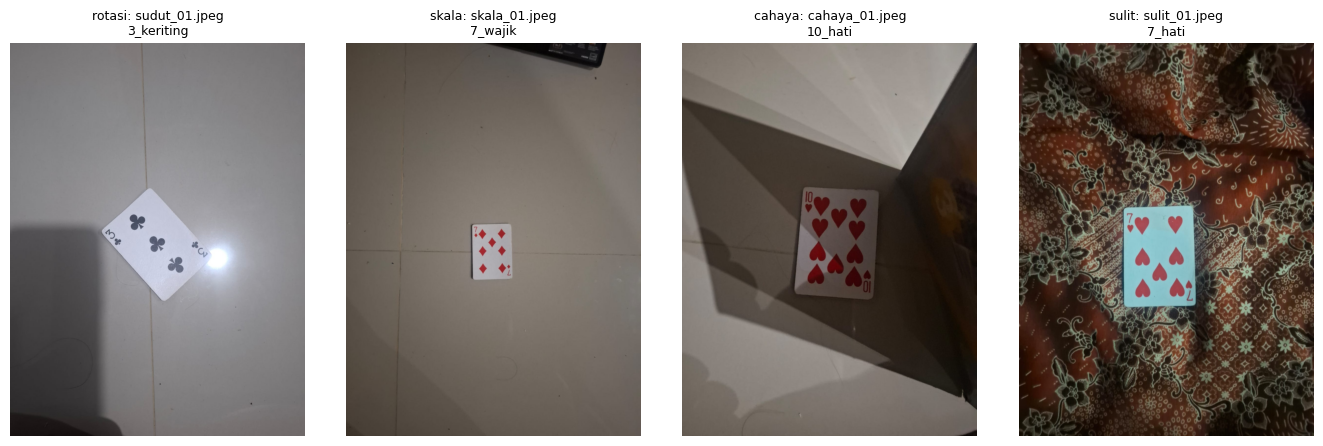

In [3]:
# Contoh 1 citra per kondisi dalam satu figure (Prak 2)
contoh = []
for k in urut_kondisi:
    r = next(r for r in ROWS if r['kondisi'] == k)
    contoh.append((f"{k}: {r['file'].split('/')[-1]}\n{r['kartu']}", ambil_gambar(r['file'])))
tampil_banyak(contoh, kolom=len(contoh), ukuran=(3.4, 4.4))

12 template dimuat (seharusnya 12).


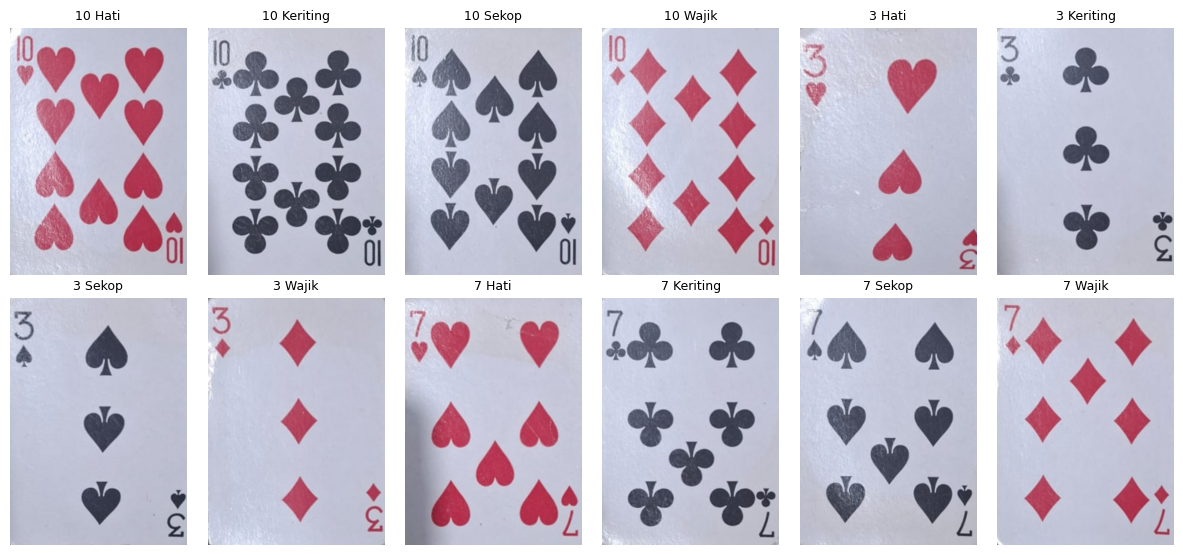

Jumlah keypoint per template
+-------------+-----+------+
| Template    | ORB | SIFT |
+-------------+-----+------+
| 10_hati     | 470 | 742  |
| 10_keriting | 500 | 745  |
| 10_sekop    | 493 | 1000 |
| 10_wajik    | 471 | 922  |
| 3_hati      | 483 | 1000 |
| 3_keriting  | 500 | 973  |
| 3_sekop     | 494 | 1000 |
| 3_wajik     | 493 | 1000 |
| 7_hati      | 486 | 1000 |
| 7_keriting  | 493 | 1000 |
| 7_sekop     | 484 | 1001 |
| 7_wajik     | 484 | 1000 |
+-------------+-----+------+
Template dengan keypoint < 100 (buram atau salah potong, cek gambar template di atas): tidak ada


In [4]:
# Template: dinormalisasi ke ukuran sama (300x420) lalu ditampilkan
TEMPLATE_GAMBAR = muat_template()
print(f'{len(TEMPLATE_GAMBAR)} template dimuat (seharusnya 12).')
tampil_banyak([(nama_tampil(n), im) for n, im in TEMPLATE_GAMBAR.items()], kolom=6, ukuran=(2, 2.8))

# Database fitur template per detektor
DB = {m: bangun_db(m, TEMPLATE_GAMBAR) for m in DAFTAR_DETEKTOR}
cetak_tabel('Jumlah keypoint per template',
            ['Template'] + [m.upper() for m in DAFTAR_DETEKTOR],
            [[n] + [len(DB[m][n]['kps']) for m in DAFTAR_DETEKTOR] for n in TEMPLATE_GAMBAR])

lemah = [n for n in TEMPLATE_GAMBAR if min(len(DB[m][n]['kps']) for m in DAFTAR_DETEKTOR) < 100]
print('Template dengan keypoint < 100 (buram atau salah potong, cek gambar template di atas):', lemah if lemah else 'tidak ada')

### Cek label ground truth
Gambar di bawah adalah kartu hasil warp (kandidat terbesar) beserta label di `ground_truth.csv`. Pemeriksaan ini dilakukan sebelum evaluasi karena label yang tidak sesuai isi foto membuat akurasi tampak lebih buruk dari sebenarnya. Dari pemeriksaan ini satu label diperbaiki: `sudut_04` semula tertulis 10 Wajik, padahal kartunya 7 Wajik (tujuh simbol dan angka 7 di pojok). Pada foto yang kartunya tidak terdeteksi (`sudut_10`, `sulit_01`, `sulit_02`, `sulit_05`, `sulit_07`) gambar yang tampil bukan kartu, sehingga labelnya dicek langsung ke foto asli. Foto dua kartu hanya menampilkan satu kartu.

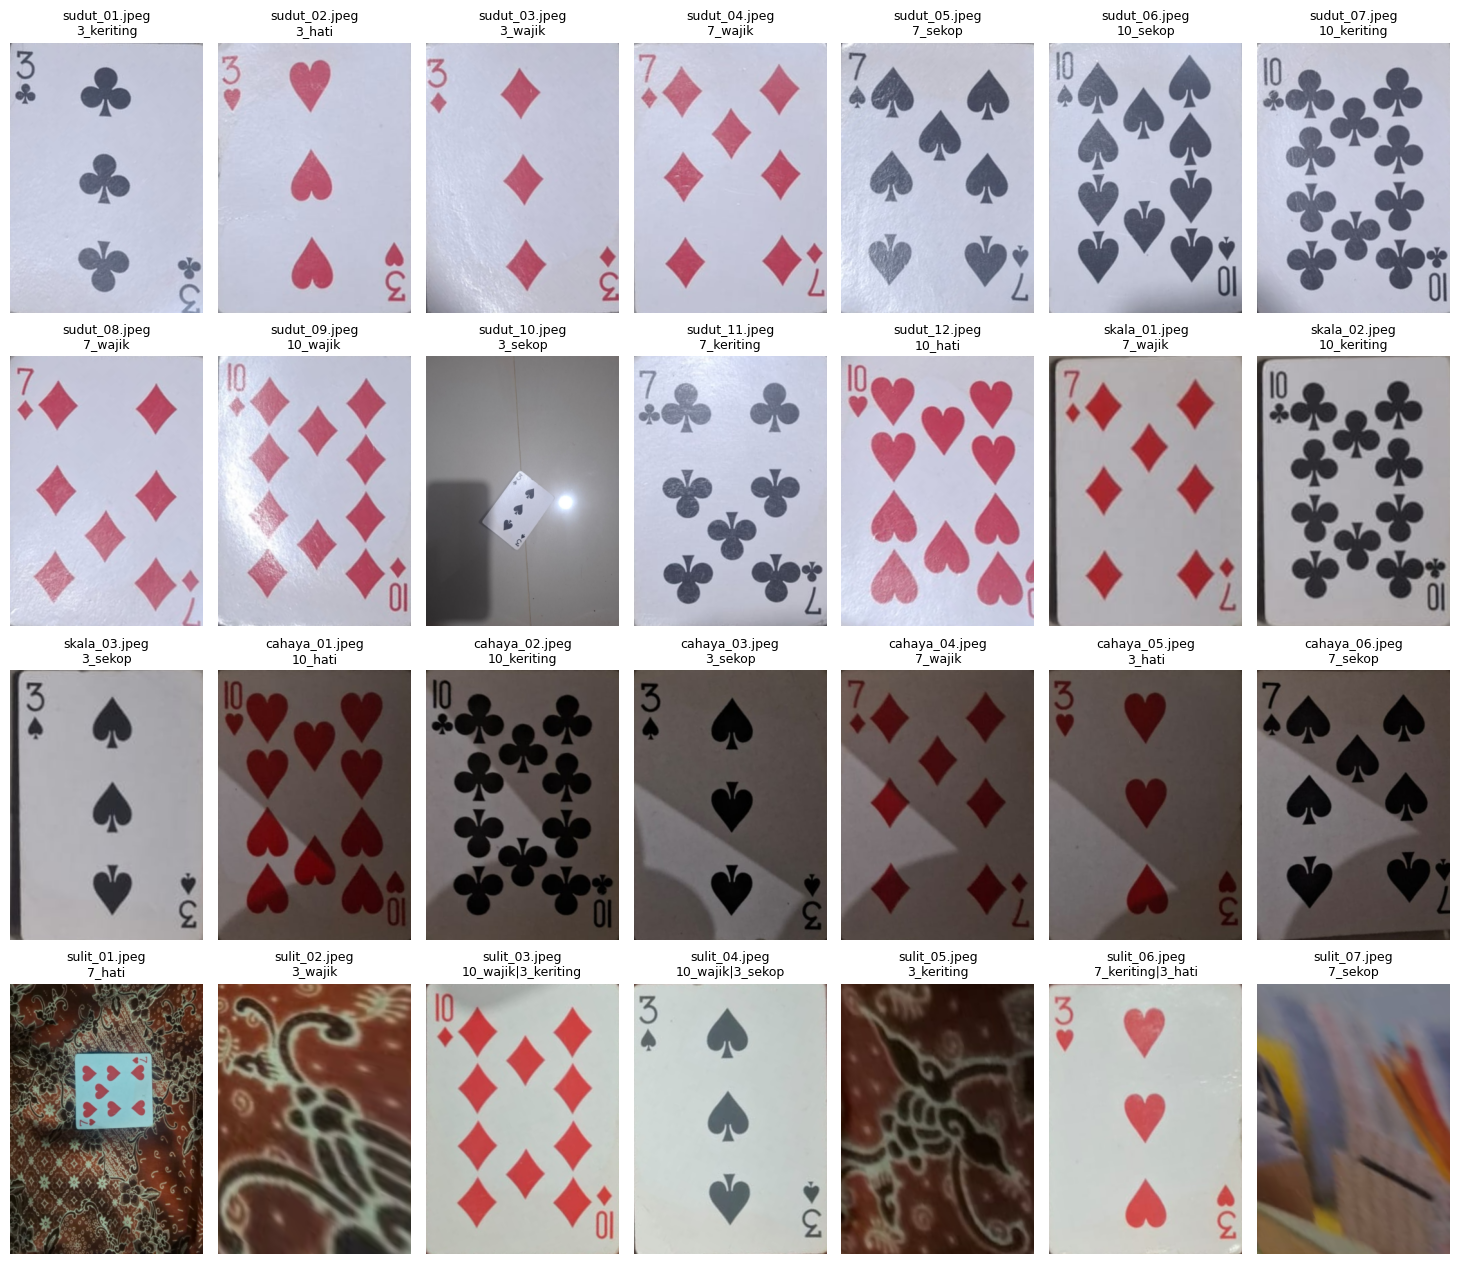

In [5]:
daftar = []
for r in ROWS:
    kand = ambil_kandidat(r['file'])
    if kand:
        daftar.append((f"{r['file'].split('/')[-1]}\n{r['kartu']}", kand[0]['warp']))
    else:
        daftar.append((f"{r['file'].split('/')[-1]}\n{r['kartu']}\n(tidak terdeteksi)", np.zeros((420, 300, 3), np.uint8)))
tampil_banyak(daftar, kolom=7, ukuran=(2.1, 3.2))

## 4. Pipeline langkah demi langkah

Alur: **foto → grayscale → blur → segmentasi → kontur 4 sudut → warp tegak → fitur ORB/SIFT → matching ke 12 template → hasil**.

### Alasan pemilihan metode dan parameter

| Tahap | Pilihan | Alasan |
|---|---|---|
| Resize | sisi terpanjang 1000 px, `INTER_AREA` | Sesuai soal (800-1200 px); `INTER_AREA` cocok untuk memperkecil citra (Prak 3). |
| Blur | Gaussian 7x7 | Nilai yang dipakai di modul Prak 3; meredam derau tekstur latar tanpa menghilangkan tepi kartu. |
| Segmentasi | Otsu, adaptive threshold, dan Canny; kandidat digabung | Satu metode bisa gagal pada latar tertentu: Otsu terganggu bayangan, adaptive mengatasi pencahayaan tidak merata (Prak 3), Canny memakai tepi sehingga tidak bergantung pada kecerahan. |
| Morfologi | close 5x5 / 7x7 | Menutup celah kecil di tepi kartu agar kontur tertutup. |
| Bentuk kartu | `convexHull` + `approxPolyDP` (epsilon 2-6% keliling) | Sudut kartu membulat sehingga epsilon kecil menghasilkan lebih dari 4 titik; epsilon dinaikkan bertahap sampai tepat 4. |
| Saringan kandidat | luas 1-60% foto; skor = luas x kemiripan rasio 1,4 x kemiripan sudut 90 derajat; kandidat < 35% kandidat terbesar dibuang | Membuang kontur bukan kartu. Pantulan lampu yang menempel pada kartu membuat kontur berbentuk jajar genjang miring, sehingga syarat sudut mendekati 90 derajat memilih kontur kartu yang sebenarnya. |
| Pelurusan | `findHomography` 4 titik + `warpPerspective` dari **foto resolusi penuh** (titik dikalikan faktor resize), lalu `resize` `INTER_AREA` ke 300x420, sisi pendek di atas | Kartu di foto 1000 px hanya sekitar 150 px; memperbesarnya ke 300x420 membuat buram dan keypoint SIFT sangat sedikit. Warp dari foto asli menghasilkan kartu tajam (Prak 3 dan 5). Sisa ambiguitas 0 atau 180 derajat dicoba keduanya dengan `getRotationMatrix2D` + `warpAffine` (Prak 3). |
| Fitur | ORB dan SIFT dibandingkan | ORB cepat dan biner; SIFT lebih tahan rotasi dan skala (Prak 5). |
| Pra-fitur | `equalizeHist` | Menyamakan kontras foto redup dengan template terang (Prak 3). |
| Matching | `BFMatcher` (Hamming untuk ORB, L2 untuk SIFT), `knnMatch` k=2, ratio test 0,75 | Nilai 0,75 dari modul Prak 5; 0,6 / 0,7 / 0,8 dibandingkan di bagian 6. |
| Filter warna | HSV: template dibatasi ke warna yang sama (merah: hati dan wajik; hitam: keriting dan sekop) | Matching hanya memakai tingkat keabuan, padahal 3 Hati dan 3 Keriting punya tata letak sama. Warna adalah pembeda yang pasti; ketepatan deteksi warna dicek di bagian 6 dan dibandingkan dengan tanpa filter. |
| Keputusan | template dengan good match terbanyak | Sesuai soal; skor alternatif (inlier RANSAC) dibandingkan di bagian 6. |
| Ambang "tidak dikenali" | ditentukan dari histogram skor di bagian 5 | Tidak ditebak: dipilih dari sebaran skor kartu benar dan salah. |

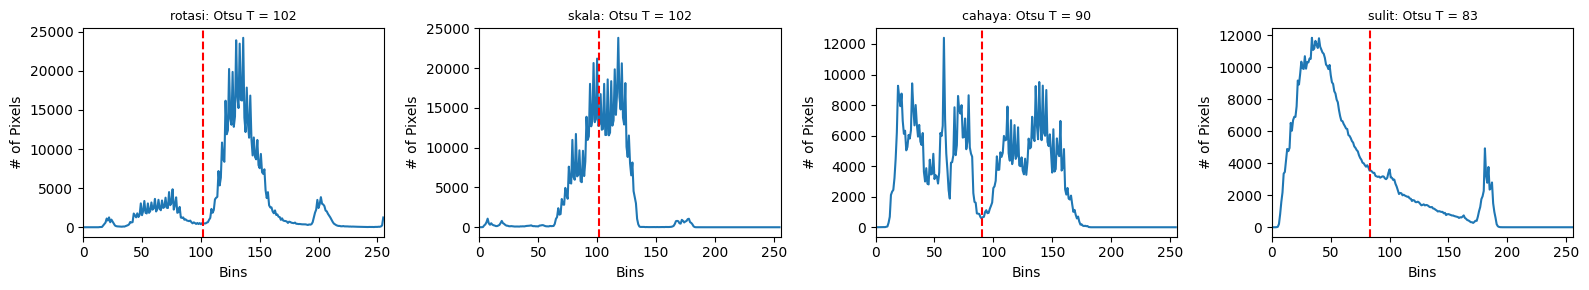

In [6]:
# Histogram grayscale dan nilai Otsu (Prak 3) untuk satu foto per kondisi: dasar pemilihan segmentasi
fig = plt.figure(figsize=(4 * len(urut_kondisi), 3))
for i, k in enumerate(urut_kondisi, 1):
    r = next(r for r in ROWS if r['kondisi'] == k)
    gray, blur = praproses(ambil_gambar(r['file']))
    T, _ = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    fig.add_subplot(1, len(urut_kondisi), i)
    plt.plot(hist)
    plt.axvline(T, color='r', linestyle='--')
    plt.xlim([0, 256])
    plt.title(f'{k}: Otsu T = {T:.0f}', fontsize=9)
    plt.xlabel('Bins')
    plt.ylabel('# of Pixels')
plt.tight_layout()
plt.show()

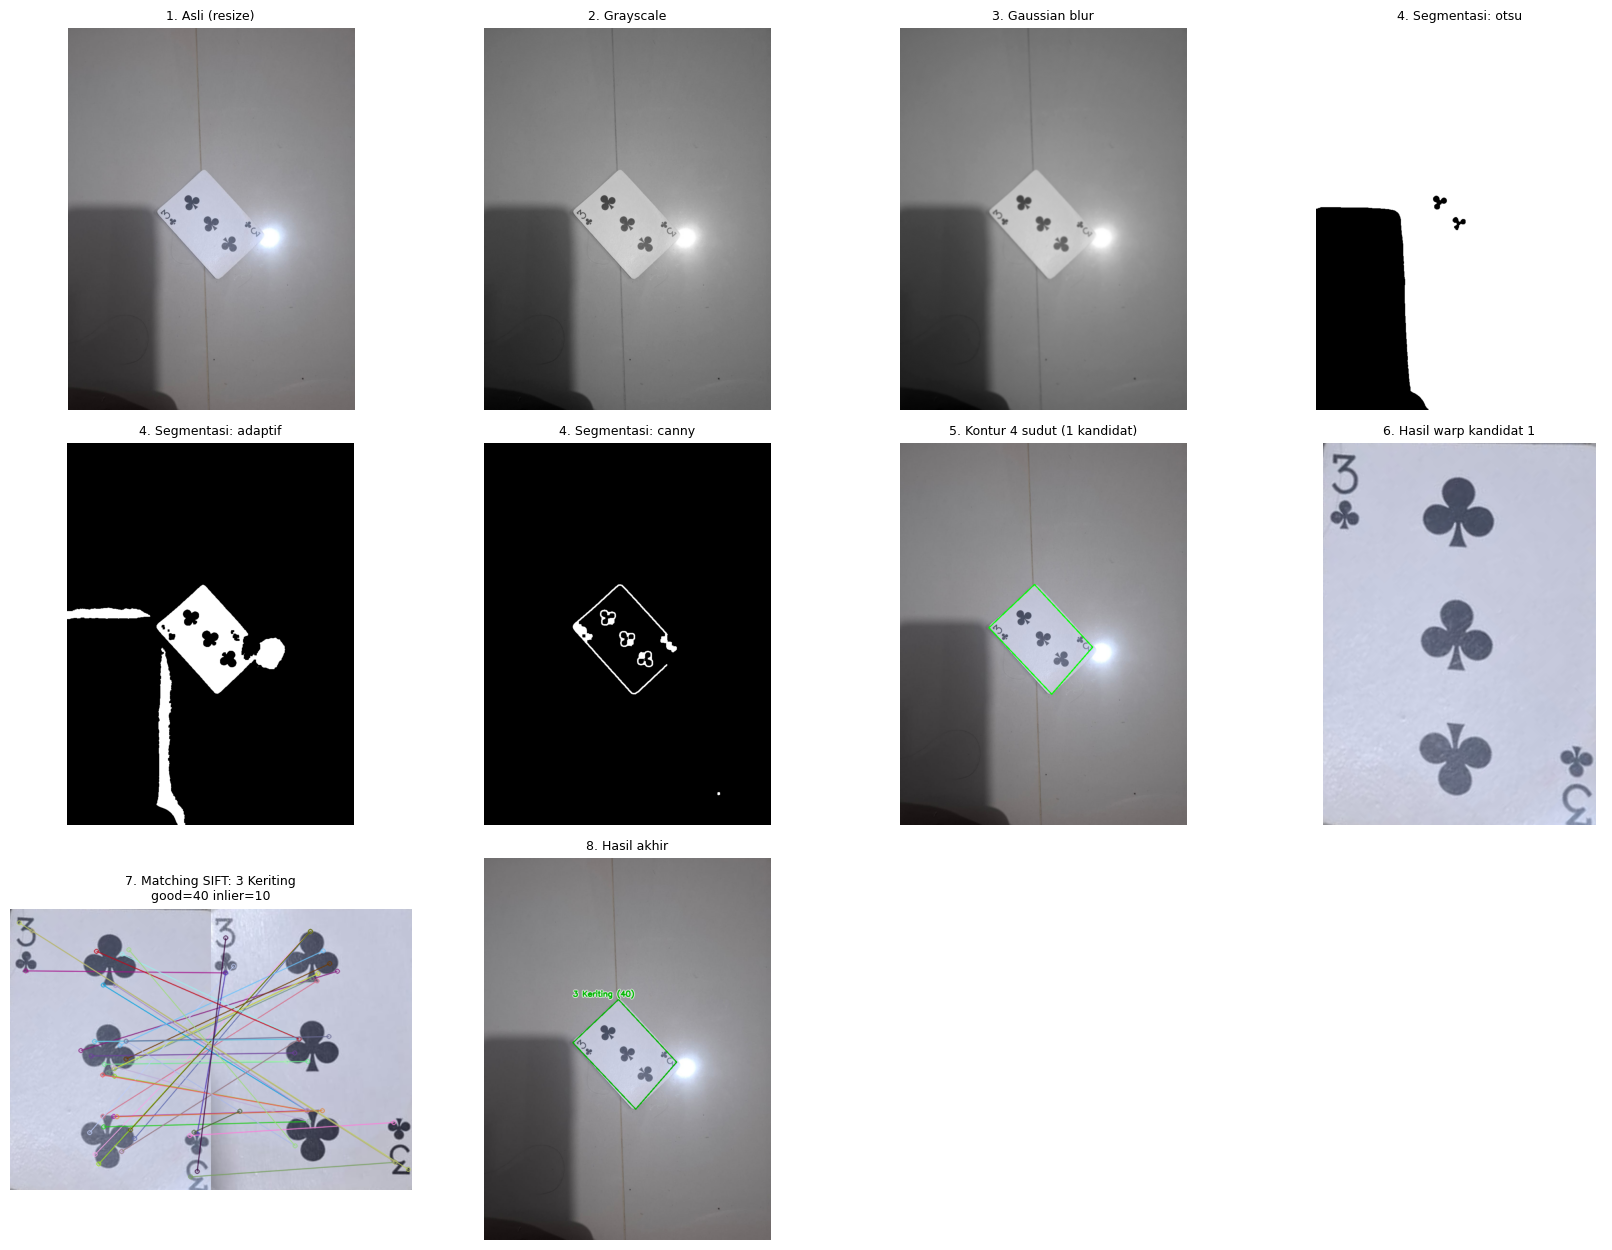

Kebenaran (ground truth): 3_keriting


In [7]:
CONTOH_FILE = ROWS[0]['file']   # ganti dengan file lain untuk melihat langkah-langkahnya


def tampilkan_langkah(rel, method=DETEKTOR_UTAMA):
    img = ambil_gambar(rel)
    gray, blur = praproses(img)
    daftar = [('1. Asli (resize)', img), ('2. Grayscale', gray), ('3. Gaussian blur', blur)]
    for s in STRATEGI:
        daftar.append((f'4. Segmentasi: {s}', segmentasi(blur, s)))
    kand = ambil_kandidat(rel)
    vis = img.copy()
    for k in kand:
        cv2.polylines(vis, [k['quad'].astype(np.int32)], True, (0, 255, 0), max(2, img.shape[1] // 300))
    daftar.append((f'5. Kontur 4 sudut ({len(kand)} kandidat)', vis))
    for i, k in enumerate(kand[:2]):
        daftar.append((f'6. Hasil warp kandidat {i + 1}', k['warp']))
    hasil = kenali_gambar(img, method, kandidat=kand)
    for i, h in enumerate(hasil[:2]):
        gm = gambar_match(h)
        if gm is not None:
            daftar.append((f"7. Matching {method.upper()}: {nama_tampil(h['nama'])}\ngood={h['good']} inlier={h['inlier']}", gm))
    daftar.append(('8. Hasil akhir', gambar_hasil(img, hasil)))
    tampil_banyak(daftar, kolom=4, ukuran=(4.2, 4.2))
    return hasil


_ = tampilkan_langkah(CONTOH_FILE)
print('Kebenaran (ground truth):', next(r['kartu'] for r in ROWS if r['file'] == CONTOH_FILE))

Sel berikut memeriksa deteksi kartu pada seluruh foto uji. Jumlah kandidat yang lebih banyak dari jumlah kartu (bayangan, pantulan lampu, tepi benda lain) tidak jadi masalah selama kandidat palsu ditolak oleh ambang skor di tahap pencocokan. Status `cadangan boundingRect` berarti kontur 4 sudut kartu tidak ditemukan sama sekali (terjadi pada `sudut_10` dan `sulit_01`). Status `ok` hanya berarti ada kandidat, bukan berarti kandidat itu kartu: pada `sulit_02`, `sulit_05`, dan `sulit_07` kandidat yang dipilih ternyata bukan kartu (dibahas di bagian 7).

In [8]:
baris = []
for r in ROWS:
    kand = ambil_kandidat(r['file'])
    harap = len(r['set_kartu'])
    status = 'ok' if len(kand) >= harap else 'KURANG'
    if kand and all(k['cadangan'] for k in kand):
        status += ' (cadangan boundingRect)'
    baris.append((r['file'], harap, len(kand), status))
cetak_tabel('Jumlah kandidat kartu vs jumlah kartu sebenarnya', ['File', 'Sebenarnya', 'Kandidat', 'Status'], baris)

Jumlah kandidat kartu vs jumlah kartu sebenarnya
+-----------------------+------------+----------+----------------------------+
| File                  | Sebenarnya | Kandidat | Status                     |
+-----------------------+------------+----------+----------------------------+
| rotasi/sudut_01.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_02.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_03.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_04.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_05.jpeg  | 1          | 2        | ok                         |
| rotasi/sudut_06.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_07.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_08.jpeg  | 1          | 1        | ok                         |
| rotasi/sudut_09.jpeg  | 1          | 1        | ok                         |
| r

## 5. Evaluasi

Pipeline dijalankan pada **seluruh** foto uji. Sebuah foto dihitung **benar** bila himpunan kartu yang dikenali sama persis dengan `ground_truth.csv` (foto dua kartu: kedua kartu harus benar).

Template tidak dipakai sebagai foto uji, sehingga akurasi mengukur kemampuan generalisasi pipeline.

In [9]:
HASIL = {m: evaluasi(ROWS, m) for m in DAFTAR_DETEKTOR}

items = HASIL[DETEKTOR_UTAMA]
baris = []
for it in items:
    r = it['row']
    skor = ', '.join(f"{h['good']}" for h in it['hasil']) or '-'
    baris.append((r['file'], r['kondisi'], r['kartu'], '|'.join(it['pred']) or '-', skor, 'BENAR' if it['benar'] else 'salah'))
cetak_tabel(f'Hasil per citra ({DETEKTOR_UTAMA.upper()})', ['File', 'Kondisi', 'Kebenaran', 'Prediksi', 'Good match', 'Hasil'], baris)

grup = akurasi_per(items, lambda it: it['row']['kondisi'])
baris = [(k, persen(*grup[k])) for k in urut_kondisi]
baris.append(('SEMUA', persen(sum(int(it['benar']) for it in items), len(items))))
cetak_tabel(f'Akurasi per kondisi ({DETEKTOR_UTAMA.upper()})', ['Kondisi', 'Akurasi'], baris)

Hasil per citra (SIFT)
+-----------------------+---------+---------------------+---------------------+------------+-------+
| File                  | Kondisi | Kebenaran           | Prediksi            | Good match | Hasil |
+-----------------------+---------+---------------------+---------------------+------------+-------+
| rotasi/sudut_01.jpeg  | rotasi  | 3_keriting          | 3_keriting          | 40         | BENAR |
| rotasi/sudut_02.jpeg  | rotasi  | 3_hati              | 3_wajik             | 30         | salah |
| rotasi/sudut_03.jpeg  | rotasi  | 3_wajik             | 3_wajik             | 24         | BENAR |
| rotasi/sudut_04.jpeg  | rotasi  | 7_wajik             | 7_wajik             | 82         | BENAR |
| rotasi/sudut_05.jpeg  | rotasi  | 7_sekop             | 7_sekop             | 51, 0      | BENAR |
| rotasi/sudut_06.jpeg  | rotasi  | 10_sekop            | 10_sekop            | 106        | BENAR |
| rotasi/sudut_07.jpeg  | rotasi  | 10_keriting         | 10_keritin

### Menentukan ambang "tidak dikenali" dari data
Histogram membandingkan skor kandidat yang kartunya **benar** dengan yang **salah**. Ambang yang baik berada di antara dua kelompok. Jika kedua kelompok bertumpuk, itu menjadi bahan analisis keterbatasan.

ORB: skor terendah kartu benar = 0, skor tertinggi kartu salah = 47
SIFT: skor terendah kartu benar = 3, skor tertinggi kartu salah = 43


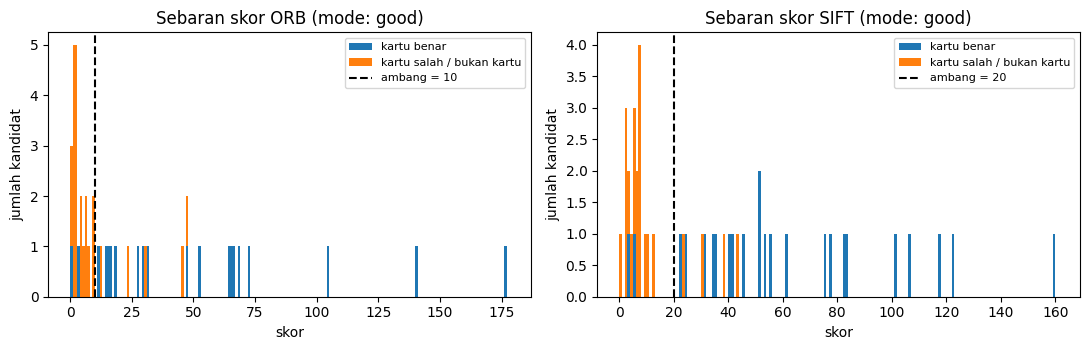

In [10]:
def kumpulkan_skor(items):
    benar, salah = [], []
    for it in items:
        for h in it['hasil']:
            (benar if h['nama'] in it['row']['set_kartu'] else salah).append(h['skor'])
    return benar, salah


fig = plt.figure(figsize=(5.5 * len(DAFTAR_DETEKTOR), 3.6))
for i, m in enumerate(DAFTAR_DETEKTOR, 1):
    fig.add_subplot(1, len(DAFTAR_DETEKTOR), i)
    sb, ss = kumpulkan_skor(HASIL[m])
    maks = max(sb + ss + [AMBANG[SKOR_MODE][m]]) + 2
    plt.hist([sb, ss], bins=range(0, int(maks) + 1), label=['kartu benar', 'kartu salah / bukan kartu'], stacked=True)
    plt.axvline(AMBANG[SKOR_MODE][m], color='k', linestyle='--', label=f'ambang = {AMBANG[SKOR_MODE][m]}')
    plt.title(f'Sebaran skor {m.upper()} (mode: {SKOR_MODE})')
    plt.xlabel('skor')
    plt.ylabel('jumlah kandidat')
    plt.legend(fontsize=8)
    print(f'{m.upper()}: skor terendah kartu benar = {min(sb) if sb else "-"}, '
          f'skor tertinggi kartu salah = {max(ss) if ss else "-"}')
plt.tight_layout()
plt.show()

## 6. Eksperimen pembanding: ORB vs SIFT

Dibandingkan pada pipeline yang sama (deteksi dan pelurusan kartu sama; hanya detektor fitur yang berbeda): akurasi, jumlah keypoint, jumlah good match, waktu proses (ekstraksi fitur + matching ke 12 template, tanpa deteksi kartu), lalu akurasi per sudut rotasi dan per jarak (skala).

In [11]:
def rata(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else 0.0


kepala = ['Metrik'] + [m.upper() for m in DAFTAR_DETEKTOR]
baris = [['Akurasi total'] + [persen(sum(int(i['benar']) for i in HASIL[m]), len(HASIL[m])) for m in DAFTAR_DETEKTOR]]
for k in urut_kondisi:
    baris.append([f'  akurasi {k}'] + [persen(*akurasi_per(HASIL[m], lambda it: it['row']['kondisi'])[k]) for m in DAFTAR_DETEKTOR])
baris.append(['Rata-rata keypoint per kartu'] + [f"{rata(h['n_kp'] for i in HASIL[m] for h in i['hasil']):.0f}" for m in DAFTAR_DETEKTOR])
baris.append(['Rata-rata good match (kartu diterima)'] + [f"{rata(h['good'] for i in HASIL[m] for h in i['hasil'] if h['diterima']):.1f}" for m in DAFTAR_DETEKTOR])
baris.append(['Rata-rata inlier RANSAC (kartu diterima)'] + [f"{rata(h['inlier'] for i in HASIL[m] for h in i['hasil'] if h['diterima']):.1f}" for m in DAFTAR_DETEKTOR])
baris.append(['Waktu pengenalan (ms/foto)'] + [f"{1000 * rata(i['waktu'] for i in HASIL[m]):.0f}" for m in DAFTAR_DETEKTOR])
cetak_tabel('ORB vs SIFT: ringkasan', kepala, baris)

ORB vs SIFT: ringkasan
+------------------------------------------+---------------+---------------+
| Metrik                                   | ORB           | SIFT          |
+------------------------------------------+---------------+---------------+
| Akurasi total                            | 53.6% (15/28) | 67.9% (19/28) |
|   akurasi rotasi                         | 66.7% (8/12)  | 83.3% (10/12) |
|   akurasi skala                          | 66.7% (2/3)   | 66.7% (2/3)   |
|   akurasi cahaya                         | 83.3% (5/6)   | 66.7% (4/6)   |
|   akurasi sulit                          | 0.0% (0/7)    | 42.9% (3/7)   |
| Rata-rata keypoint per kartu             | 388           | 505           |
| Rata-rata good match (kartu diterima)    | 51.0          | 61.5          |
| Rata-rata inlier RANSAC (kartu diterima) | 32.6          | 29.3          |
| Waktu pengenalan (ms/foto)               | 109           | 439           |
+------------------------------------------+---------

Akurasi per sudut rotasi (derajat)
+-------+--------------+-------------+
| Sudut | ORB          | SIFT        |
+-------+--------------+-------------+
| 45    | 50.0% (4/8)  | 87.5% (7/8) |
| 90    | 100.0% (4/4) | 75.0% (3/4) |
+-------+--------------+-------------+


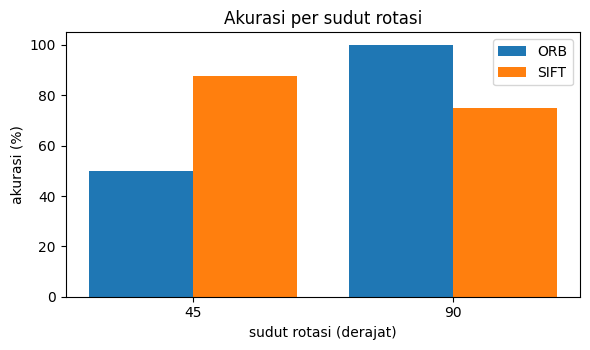

Akurasi per jarak pemotretan (cm)
+------------+--------------+---------------+
| Jarak (cm) | ORB          | SIFT          |
+------------+--------------+---------------+
| 25         | 66.7% (8/12) | 83.3% (10/12) |
| 40         | 66.7% (2/3)  | 66.7% (2/3)   |
+------------+--------------+---------------+


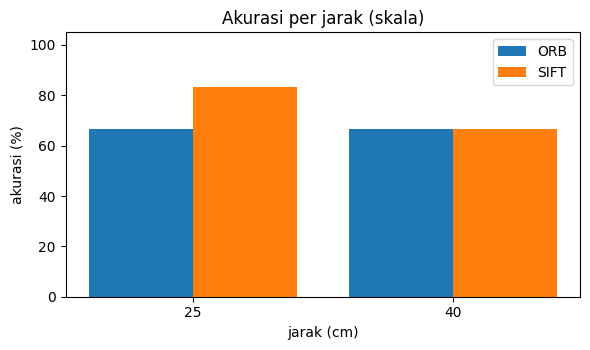

In [12]:
def tabel_per(judul, nama_kolom, fungsi_kunci, filter_kondisi):
    kunci = sorted({fungsi_kunci(i) for m in DAFTAR_DETEKTOR for i in HASIL[m]
                    if i['row']['kondisi'] in filter_kondisi and fungsi_kunci(i) is not None})
    baris, nilai = [], {m: [] for m in DAFTAR_DETEKTOR}
    for k in kunci:
        b = [k]
        for m in DAFTAR_DETEKTOR:
            sub = [i for i in HASIL[m] if i['row']['kondisi'] in filter_kondisi and fungsi_kunci(i) == k]
            ok = sum(int(i['benar']) for i in sub)
            b.append(persen(ok, len(sub)))
            nilai[m].append(100 * ok / len(sub) if sub else 0)
        baris.append(b)
    cetak_tabel(judul, [nama_kolom] + [m.upper() for m in DAFTAR_DETEKTOR], baris)
    return kunci, nilai


def grafik_bar(kunci, nilai, judul, xlabel):
    if not kunci:
        return
    x = np.arange(len(kunci))
    lebar = 0.8 / len(DAFTAR_DETEKTOR)
    plt.figure(figsize=(6, 3.6))
    for j, m in enumerate(DAFTAR_DETEKTOR):
        plt.bar(x + j * lebar, nilai[m], lebar, label=m.upper())
    plt.xticks(x + lebar * (len(DAFTAR_DETEKTOR) - 1) / 2, [str(k) for k in kunci])
    plt.ylim(0, 105)
    plt.ylabel('akurasi (%)')
    plt.xlabel(xlabel)
    plt.title(judul)
    plt.legend()
    plt.tight_layout()
    plt.show()


k_rot, v_rot = tabel_per('Akurasi per sudut rotasi (derajat)', 'Sudut', lambda i: i['row']['rotasi'], KONDISI_ROTASI)
grafik_bar(k_rot, v_rot, 'Akurasi per sudut rotasi', 'sudut rotasi (derajat)')
k_skl, v_skl = tabel_per('Akurasi per jarak pemotretan (cm)', 'Jarak (cm)', lambda i: i['row']['jarak'], KONDISI_SKALA)
grafik_bar(k_skl, v_skl, 'Akurasi per jarak (skala)', 'jarak (cm)')

### Eksperimen tambahan: ratio test, jenis skor, filter warna
Ratio test 0,6 / 0,7 / 0,8, perbandingan skor *good match* vs *inlier* RANSAC (dengan ambang masing-masing), dan filter warna HSV (Prak 3) yang membatasi template ke kelompok warna yang sama (merah: hati dan wajik; hitam: keriting dan sekop).

In [13]:
# Ketepatan deteksi warna HSV (dasar keputusan memakai filter warna): kartu uji satu kartu dan template
benar = tot = 0
for r in ROWS:
    if len(r['set_kartu']) != 1:
        continue
    kand = ambil_kandidat(r['file'])
    if not kand or kand[0]['cadangan']:
        continue
    tot += 1
    benar += int(warna_kartu(kand[0]['warp']) == warna_dari_nama(next(iter(r['set_kartu']))))
print('Ketepatan warna HSV pada kartu uji :', persen(benar, tot))
print('Ketepatan warna HSV pada template  :', persen(sum(warna_kartu(im) == warna_dari_nama(n) for n, im in TEMPLATE_GAMBAR.items()), len(TEMPLATE_GAMBAR)))

KONFIG = [
    ('dasar (rasio 0,75; skor good match; filter warna HSV)', {}),
    ('tanpa filter warna HSV', {'filter_warna': False}),
    ('rasio 0,6', {'rasio': 0.6}),
    ('rasio 0,7', {'rasio': 0.7}),
    ('rasio 0,8', {'rasio': 0.8}),
    ('skor = inlier RANSAC', {'skor_mode': 'inlier'}),
]
baris = []
ABL = {}
for nama_k, kw in KONFIG:
    b = [nama_k]
    for m in DAFTAR_DETEKTOR:
        it = HASIL[m] if not kw else evaluasi(ROWS, m, **kw)
        ABL[(nama_k, m)] = sum(int(i['benar']) for i in it)
        b.append(persen(ABL[(nama_k, m)], len(it)))
    baris.append(b)
cetak_tabel('Akurasi total per konfigurasi', ['Konfigurasi'] + [m.upper() for m in DAFTAR_DETEKTOR], baris)

Ketepatan warna HSV pada kartu uji : 91.3% (21/23)
Ketepatan warna HSV pada template  : 100.0% (12/12)
Akurasi total per konfigurasi
+-------------------------------------------------------+---------------+---------------+
| Konfigurasi                                           | ORB           | SIFT          |
+-------------------------------------------------------+---------------+---------------+
| dasar (rasio 0,75; skor good match; filter warna HSV) | 53.6% (15/28) | 67.9% (19/28) |
| tanpa filter warna HSV                                | 50.0% (14/28) | 50.0% (14/28) |
| rasio 0,6                                             | 25.0% (7/28)  | 35.7% (10/28) |
| rasio 0,7                                             | 46.4% (13/28) | 60.7% (17/28) |
| rasio 0,8                                             | 60.7% (17/28) | 67.9% (19/28) |
| skor = inlier RANSAC                                  | 46.4% (13/28) | 46.4% (13/28) |
+-------------------------------------------------------+

### Analisis eksperimen

Angka di bawah dihitung dari hasil evaluasi di atas, sehingga selalu sama dengan tabel.

In [14]:
from IPython.display import Markdown, display


def hit(m, kond=None, sudut=None):
    its = [i for i in HASIL[m] if (kond is None or i['row']['kondisi'] == kond)
           and (sudut is None or (i['row']['kondisi'] == 'rotasi' and i['row']['rotasi'] == sudut))]
    return sum(int(i['benar']) for i in its), len(its)


def pr(bt):
    return f'{100 * bt[0] / bt[1]:.0f}% ({bt[0]}/{bt[1]})'


def ms(m):
    return 1000 * rata(i['waktu'] for i in HASIL[m])


def kp(m):
    return rata(h['n_kp'] for i in HASIL[m] for h in i['hasil'])


def abl(nama, m):
    return ABL[(nama, m)]


N = len(ROWS)
T = {m: hit(m) for m in ('orb', 'sift')}
display(Markdown(f"""
**ORB dan SIFT.** Dengan deteksi dan pelurusan kartu yang sama, SIFT lebih akurat: {pr(T['sift'])} berbanding {pr(T['orb'])} untuk ORB. Selisih terbesar ada pada kartu yang diputar 45° (SIFT {pr(hit('sift', 'rotasi', 45))}, ORB {pr(hit('orb', 'rotasi', 45))}) dan pada foto sulit (SIFT {pr(hit('sift', 'sulit'))}, ORB {pr(hit('orb', 'sulit'))}). ORB tidak mengenali satu pun foto sulit, termasuk tiga foto dua kartu yang dikenali SIFT, padahal kedua kartu pada foto itu sudah terdeteksi dan diluruskan dengan benar (tabel kandidat di bagian 4), jadi penyebabnya ada pada tahap pencocokan. Pada kondisi cahaya ORB sedikit di atas SIFT ({pr(hit('orb', 'cahaya'))} berbanding {pr(hit('sift', 'cahaya'))}), tetapi hanya ada 6 foto sehingga selisih satu foto belum cukup untuk menyimpulkan ORB lebih baik di kondisi itu. Pada skala keduanya sama ({pr(hit('sift', 'skala'))}), dan karena semua foto skala diambil pada jarak 40 cm, pengaruh ukuran kartu belum teruji penuh.

Alasan yang masuk akal untuk keunggulan SIFT: descriptor SIFT berupa 128 nilai desimal yang dibandingkan dengan jarak L2, sedangkan ORB memakai descriptor biner 256 bit dengan jarak Hamming, sehingga SIFT lebih peka terhadap perbedaan kecil bentuk simbol (sekop dengan keriting, hati dengan wajik). Jumlah keypoint juga lebih banyak pada SIFT (rata-rata {kp('sift'):.0f} per kartu, ORB {kp('orb'):.0f}). Harganya waktu: {ms('sift'):.0f} ms per foto untuk SIFT dan {ms('orb'):.0f} ms untuk ORB, sekitar {ms('sift') / ms('orb'):.0f} kali lebih lambat. Untuk 28 foto ini selisih itu tidak terasa, tetapi untuk pengenalan waktu nyata ORB lebih masuk akal.

Karena kartu sudah diluruskan dengan `warpPerspective` sebelum dicocokkan, dan template dicoba pada 0° dan 180°, rotasi 45° dan 90° sebagian besar sudah ditangani di tahap pelurusan, bukan oleh sifat invarian rotasi detektor. Karena itu akurasi pada rotasi lebih ditentukan oleh ketepatan deteksi kartu dan kemiripan simbol daripada oleh jenis detektornya.

**Ratio test.** Pada SIFT, rasio 0,6 memberi {abl('rasio 0,6', 'sift')} foto benar, rasio 0,7 memberi {abl('rasio 0,7', 'sift')}, rasio 0,75 (nilai dasar) {abl('dasar (rasio 0,75; skor good match; filter warna HSV)', 'sift')}, dan rasio 0,8 {abl('rasio 0,8', 'sift')} dari {N} foto. Rasio kecil terlalu ketat: kartu 7 dan 10 punya banyak simbol identik, sehingga jarak tetangga terdekat pertama dan kedua hampir sama dan match yang benar ikut terbuang, lalu jumlah good match jatuh di bawah ambang. Rasio 0,8 tidak lebih buruk dari 0,75 pada SIFT (ORB: {abl('rasio 0,8', 'orb')} lawan {abl('dasar (rasio 0,75; skor good match; filter warna HSV)', 'orb')}), tetapi kenaikannya kecil dan rasio yang longgar lebih mudah meloloskan match yang salah, jadi 0,75 dipertahankan.

**Filter warna.** Tanpa filter warna HSV, SIFT benar pada {abl('tanpa filter warna HSV', 'sift')} foto dan ORB pada {abl('tanpa filter warna HSV', 'orb')} foto; dengan filter, masing-masing {abl('dasar (rasio 0,75; skor good match; filter warna HSV)', 'sift')} dan {abl('dasar (rasio 0,75; skor good match; filter warna HSV)', 'orb')}. Filter membuang template berbeda warna (mis. 3 Keriting untuk kartu merah) yang sebelumnya bersaing karena tata letak simbolnya sama. Filter ini bergantung pada deteksi warna yang benar pada 21 dari 23 kartu uji dan semua template (ketepatan HSV di atas). Filter tidak bisa membedakan hati dari wajik atau sekop dari keriting, dan itu terbukti menjadi sumber kesalahan utama (bagian 7).

**Skor.** Memakai jumlah inlier RANSAC sebagai skor memberi {abl('skor = inlier RANSAC', 'sift')} foto benar pada SIFT, lebih rendah daripada good match. Dugaan kami, jumlah inlier pada kartu yang benar kecil dan berdekatan dengan kartu yang salah sehingga ambangnya sulit dipisahkan; good match lebih mudah dipisah dengan satu ambang.
"""))


**ORB dan SIFT.** Dengan deteksi dan pelurusan kartu yang sama, SIFT lebih akurat: 68% (19/28) berbanding 54% (15/28) untuk ORB. Selisih terbesar ada pada kartu yang diputar 45° (SIFT 88% (7/8), ORB 50% (4/8)) dan pada foto sulit (SIFT 43% (3/7), ORB 0% (0/7)). ORB tidak mengenali satu pun foto sulit, termasuk tiga foto dua kartu yang dikenali SIFT, padahal kedua kartu pada foto itu sudah terdeteksi dan diluruskan dengan benar (tabel kandidat di bagian 4), jadi penyebabnya ada pada tahap pencocokan. Pada kondisi cahaya ORB sedikit di atas SIFT (83% (5/6) berbanding 67% (4/6)), tetapi hanya ada 6 foto sehingga selisih satu foto belum cukup untuk menyimpulkan ORB lebih baik di kondisi itu. Pada skala keduanya sama (67% (2/3)), dan karena semua foto skala diambil pada jarak 40 cm, pengaruh ukuran kartu belum teruji penuh.

Alasan yang masuk akal untuk keunggulan SIFT: descriptor SIFT berupa 128 nilai desimal yang dibandingkan dengan jarak L2, sedangkan ORB memakai descriptor biner 256 bit dengan jarak Hamming, sehingga SIFT lebih peka terhadap perbedaan kecil bentuk simbol (sekop dengan keriting, hati dengan wajik). Jumlah keypoint juga lebih banyak pada SIFT (rata-rata 505 per kartu, ORB 388). Harganya waktu: 439 ms per foto untuk SIFT dan 109 ms untuk ORB, sekitar 4 kali lebih lambat. Untuk 28 foto ini selisih itu tidak terasa, tetapi untuk pengenalan waktu nyata ORB lebih masuk akal.

Karena kartu sudah diluruskan dengan `warpPerspective` sebelum dicocokkan, dan template dicoba pada 0° dan 180°, rotasi 45° dan 90° sebagian besar sudah ditangani di tahap pelurusan, bukan oleh sifat invarian rotasi detektor. Karena itu akurasi pada rotasi lebih ditentukan oleh ketepatan deteksi kartu dan kemiripan simbol daripada oleh jenis detektornya.

**Ratio test.** Pada SIFT, rasio 0,6 memberi 10 foto benar, rasio 0,7 memberi 17, rasio 0,75 (nilai dasar) 19, dan rasio 0,8 19 dari 28 foto. Rasio kecil terlalu ketat: kartu 7 dan 10 punya banyak simbol identik, sehingga jarak tetangga terdekat pertama dan kedua hampir sama dan match yang benar ikut terbuang, lalu jumlah good match jatuh di bawah ambang. Rasio 0,8 tidak lebih buruk dari 0,75 pada SIFT (ORB: 17 lawan 15), tetapi kenaikannya kecil dan rasio yang longgar lebih mudah meloloskan match yang salah, jadi 0,75 dipertahankan.

**Filter warna.** Tanpa filter warna HSV, SIFT benar pada 14 foto dan ORB pada 14 foto; dengan filter, masing-masing 19 dan 15. Filter membuang template berbeda warna (mis. 3 Keriting untuk kartu merah) yang sebelumnya bersaing karena tata letak simbolnya sama. Filter ini bergantung pada deteksi warna yang benar pada 21 dari 23 kartu uji dan semua template (ketepatan HSV di atas). Filter tidak bisa membedakan hati dari wajik atau sekop dari keriting, dan itu terbukti menjadi sumber kesalahan utama (bagian 7).

**Skor.** Memakai jumlah inlier RANSAC sebagai skor memberi 13 foto benar pada SIFT, lebih rendah daripada good match. Dugaan kami, jumlah inlier pada kartu yang benar kecil dan berdekatan dengan kartu yang salah sehingga ambangnya sulit dipisahkan; good match lebih mudah dipisah dengan satu ambang.


## 7. Analisis kegagalan

Sel di bawah menampilkan enam kegagalan SIFT yang mewakili tiga pola: kartu kembar tertukar (`sudut_02`, `skala_03`, `cahaya_06`), kartu tidak ditemukan (`sudut_10`, `sulit_01`), dan foto buram (`sulit_07`). Tiap kasus menampilkan hasil anotasi, hasil warp, dan garis matching terhadap template terbaik. Kegagalan lain dijelaskan di tabel sesudahnya.

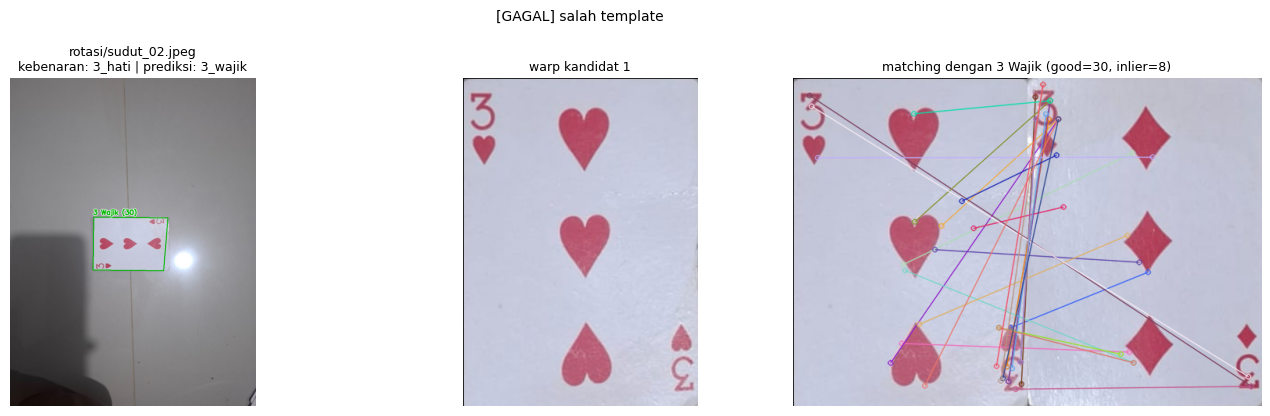

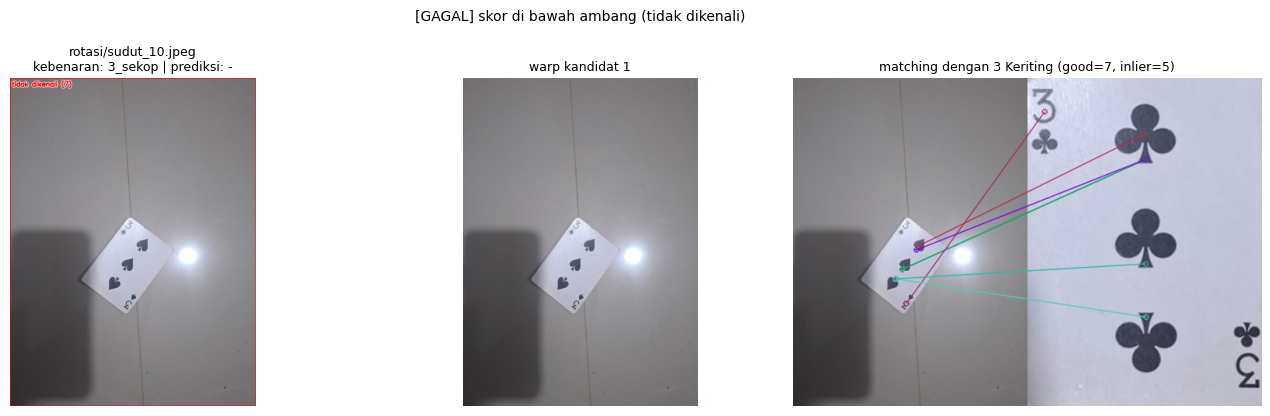

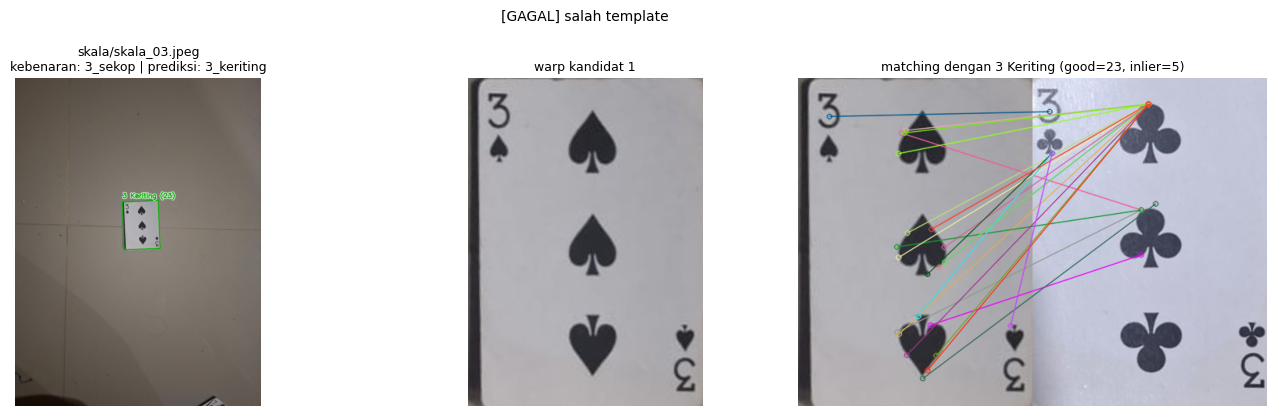

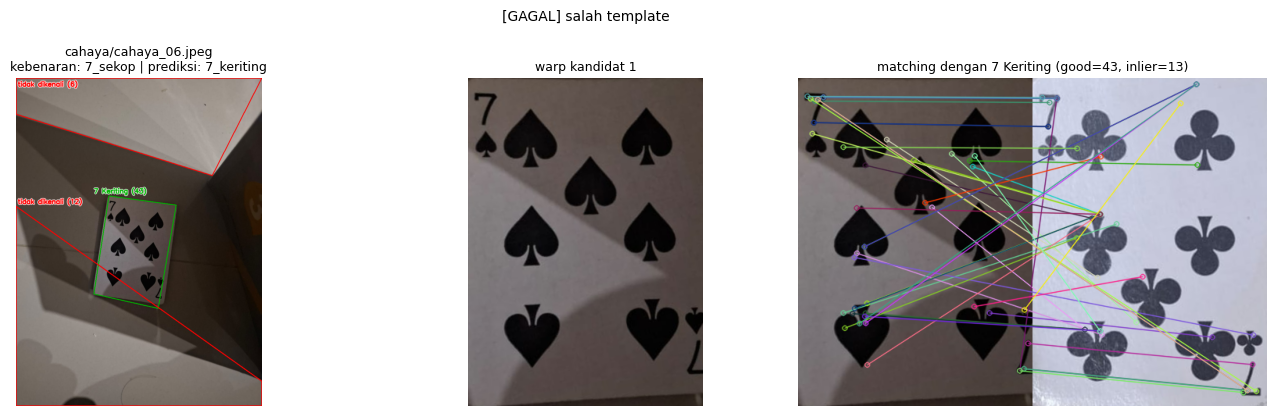

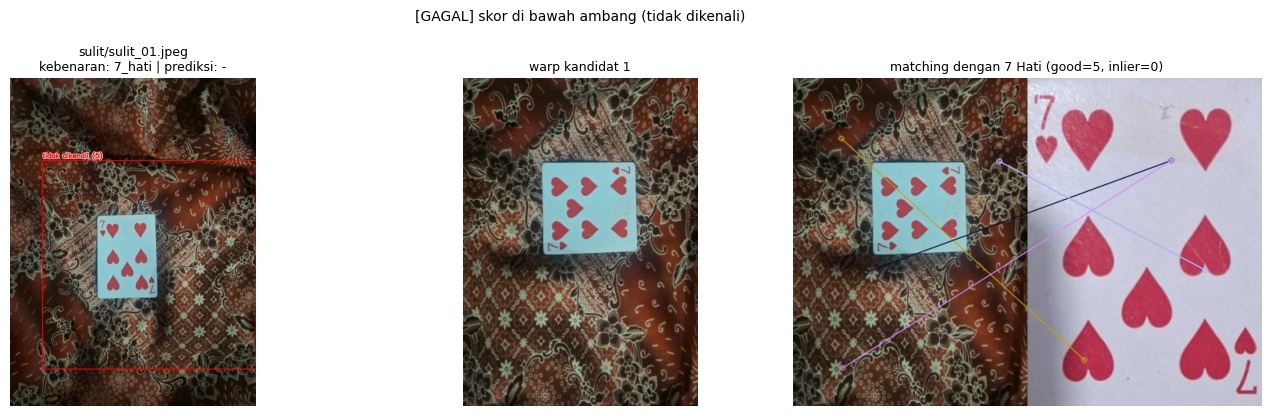

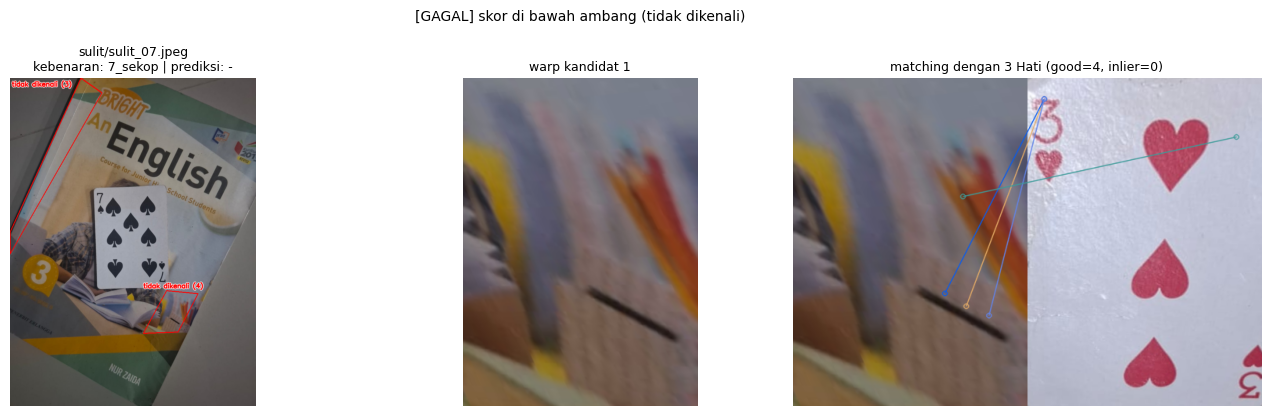

Ringkasan kasus yang dianalisis
+-----------------------+--------+-----------+------------+---------------------------------------+---------------------------------------------------------------+
| File                  | Status | Kebenaran | Prediksi   | Jenis (otomatis)                      | Penyebab singkat                                              |
+-----------------------+--------+-----------+------------+---------------------------------------+---------------------------------------------------------------+
| rotasi/sudut_02.jpeg  | GAGAL  | 3_hati    | 3_wajik    | salah template                        | 3 Hati tertukar 3 Wajik (warna dan tata letak sama)           |
| rotasi/sudut_10.jpeg  | GAGAL  | 3_sekop   | -          | skor di bawah ambang (tidak dikenali) | kartu kecil di samping pantulan lampu, kontur tidak ditemukan |
| skala/skala_03.jpeg   | GAGAL  | 3_sekop   | 3_keriting | salah template                        | 3 Sekop tertukar 3 Keriting, simbol kecil pada j

In [15]:
PILIH_FILE = ['rotasi/sudut_02.jpeg', 'rotasi/sudut_10.jpeg', 'skala/skala_03.jpeg',
              'cahaya/cahaya_06.jpeg', 'sulit/sulit_01.jpeg', 'sulit/sulit_07.jpeg']
PENYEBAB = {
    'rotasi/sudut_02.jpeg': '3 Hati tertukar 3 Wajik (warna dan tata letak sama)',
    'rotasi/sudut_04.jpeg': 'label CSV lama keliru, kartu sebenarnya 7 Wajik',
    'rotasi/sudut_10.jpeg': 'kartu kecil di samping pantulan lampu, kontur tidak ditemukan',
    'skala/skala_03.jpeg': '3 Sekop tertukar 3 Keriting, simbol kecil pada jarak 40 cm',
    'cahaya/cahaya_05.jpeg': '3 Hati tertukar 3 Wajik, bayangan menutupi kartu',
    'cahaya/cahaya_06.jpeg': '7 Sekop tertukar 7 Keriting, bayangan menutupi kartu',
    'sulit/sulit_01.jpeg': 'kartu kecil di kain batik, kontur tidak ditemukan',
    'sulit/sulit_02.jpeg': 'kandidat terpilih adalah motif batik, bukan kartu',
    'sulit/sulit_05.jpeg': 'kandidat terpilih adalah motif batik, bukan kartu',
    'sulit/sulit_07.jpeg': 'foto buram, simbol kartu tidak terbaca',
}


def tampilkan_gagal(items, n=3):
    gagal = [it for it in items if not it['benar']]
    terpilih = [it for f in PILIH_FILE for it in gagal if it['row']['file'] == f]
    if len(terpilih) >= n:
        gagal = terpilih
        n = len(terpilih)
    lemah = sorted([it for it in items if it['benar'] and it['hasil']],
                   key=lambda it: min(h['skor'] for h in it['hasil']))
    pilih = [(it, 'GAGAL') for it in gagal[:n]]
    pilih += [(it, 'LEMAH (benar tetapi skor rendah)') for it in lemah[:max(0, n - len(pilih))]]
    for it, status in pilih:
        r = it['row']
        img = ambil_gambar(r['file'])
        fig = plt.figure(figsize=(14, 4.2))
        fig.add_subplot(1, 3, 1)
        plt.imshow(cv2.cvtColor(gambar_hasil(img, it['hasil']), cv2.COLOR_BGR2RGB))
        plt.title(f"{r['file']}\nkebenaran: {r['kartu']} | prediksi: {'|'.join(it['pred']) or '-'}", fontsize=9)
        plt.axis('off')
        fig.add_subplot(1, 3, 2)
        if it['hasil']:
            plt.imshow(cv2.cvtColor(it['hasil'][0]['warp'], cv2.COLOR_BGR2RGB))
            plt.title('warp kandidat 1', fontsize=9)
        plt.axis('off')
        fig.add_subplot(1, 3, 3)
        gm = gambar_match(it['hasil'][0]) if it['hasil'] else None
        if gm is not None:
            plt.imshow(cv2.cvtColor(gm, cv2.COLOR_BGR2RGB))
            plt.title(f"matching dengan {nama_tampil(it['hasil'][0]['nama'])} "
                      f"(good={it['hasil'][0]['good']}, inlier={it['hasil'][0]['inlier']})", fontsize=9)
        plt.axis('off')
        plt.suptitle(f'[{status}] {jenis_gagal(it) if status == "GAGAL" else ""}', fontsize=10)
        plt.tight_layout()
        plt.show()
    return pilih


pilihan = tampilkan_gagal(HASIL[DETEKTOR_UTAMA], n=3)
cetak_tabel('Ringkasan kasus yang dianalisis',
            ['File', 'Status', 'Kebenaran', 'Prediksi', 'Jenis (otomatis)', 'Penyebab singkat'],
            [(it['row']['file'], st.split(' ')[0], it['row']['kartu'], '|'.join(it['pred']) or '-',
              jenis_gagal(it), PENYEBAB.get(it['row']['file'], '-')) for it, st in pilihan])

### Analisis penyebab

Kegagalan SIFT pada seluruh foto uji (nilai good match diambil dari tabel evaluasi dan gambar di atas):

| File | Penyebab | Bukti | Saran perbaikan |
|---|---|---|---|
| `sudut_02` | 3 Hati tertukar 3 Wajik. Keduanya merah dan tiga simbolnya sama-sama di tengah, jadi filter warna tidak membantu. | Good match 30 ke 3 Wajik, tetapi garis matching menyilang acak dan hanya 8 yang lolos RANSAC. | Pencocokan terbatas pada area simbol, atau tambah template dari beberapa kondisi cahaya. |
| `cahaya_05` | Kasus yang sama dengan `sudut_02`. Bayangan diagonal menutupi bagian bawah kartu sehingga simbol hati ketiga gelap. | 3 Hati terbaca 3 Wajik dengan good match 38; dua kandidat lain (9 dan 7) ditolak. | Sama seperti di atas; ekualisasi histogram lokal (CLAHE) untuk meratakan bayangan. |
| `skala_03` | 3 Sekop tertukar 3 Keriting. Sama-sama hitam dengan tata letak sama, dan pada jarak 40 cm simbol kecil sehingga bentuk pembedanya hanya diwakili sedikit keypoint. | Good match 23, hanya sedikit di atas ambang 20. | Tambah foto skala pada 15 dan 25 cm untuk memastikan penyebabnya ukuran atau kemiripan simbol. |
| `cahaya_06` | 7 Sekop tertukar 7 Keriting, pola sama dengan `skala_03`, ditambah bayangan yang memotong kartu. | Good match 43 ke 7 Keriting; dua kandidat lain (12 dan 6) ditolak. | Sama seperti `cahaya_05`. |
| `sudut_10` | Kartu tidak ditemukan. Kartunya kecil (kira-kira seperlima tinggi foto, miring 45°) di lantai terang, tepat di samping pantulan lampu, sehingga tepinya tidak membentuk kontur 4 sudut. Program memakai cadangan `boundingRect` dan seluruh foto yang dicocokkan. | Status kandidat `cadangan boundingRect`; panel warp berisi seluruh foto; good match hanya 7. | Dekatkan kamera sampai kartu mengisi sepertiga bingkai dan geser lampu supaya pantulannya tidak menempel di kartu. |
| `sulit_01` | Kartu tidak ditemukan. Kartu kecil di tengah kain batik; garis motif yang rapat menghasilkan banyak tepi sehingga kontur kartu tidak terpilih. Warna kartu juga tampak kebiruan pada foto. | Status `cadangan boundingRect`; warp berisi seluruh foto; good match 5. | Gunakan alas polos, atau cari kontur dengan syarat rasio sisi kartu lebih ketat. |
| `sulit_02`, `sulit_05` | Kandidat yang dipilih adalah potongan motif batik yang kebetulan berbentuk 4 sudut, bukan kartu. | Hasil warp hanya memperlihatkan motif batik tanpa simbol kartu; good match 2 dan 6 (`sulit_02`), 2 dan 5 (`sulit_05`), semuanya di bawah ambang; kandidat 2 padahal kartunya 1. | Sama seperti `sulit_01`. |
| `sulit_07` | Foto buram (blur gerak) pada latar sampul buku yang warna-warni, tepi buku menjadi kandidat dan simbol kartu tidak terbaca. | Hasil warp buram tanpa simbol yang terbaca; good match 4 dan 3. | Ulangi pemotretan dengan kamera stabil. Ini keterbatasan data, bukan kelemahan metode. |

Pola yang terlihat: kegagalan terbagi dua. Pertama, kartu kembar yang hanya beda simbol (hati dengan wajik, sekop dengan keriting) tertukar, dan dari garis matching pada `sudut_02` tampaknya fitur yang cocok lebih banyak berasal dari angka di pojok dan tata letak simbol yang sama daripada dari bentuk simbolnya. Kedua, kartu tidak ditemukan pada foto dengan latar bermotif atau kartu kecil di dekat pantulan lampu, sehingga pencocokan dilakukan pada gambar yang bukan kartu. Kegagalan jenis kedua sudah terlihat dari good match yang rendah, dan program menjawab "tidak dikenali" daripada menebak kartu yang salah.

Catatan label: pada ground truth awal `sudut_04` tertulis 10 Wajik. Setelah dicek ke foto, kartunya 7 Wajik dan prediksi program (7 Wajik, good match 82) benar, sehingga labelnya dikoreksi di `ground_truth.csv`. Foto `sulit_03`, `sulit_04`, dan `sulit_06` (dua kartu) dikenali semua oleh SIFT, jadi penanganan lebih dari satu kartu per foto berjalan.

## 8. Kesimpulan

In [16]:
display(Markdown(f"""
1. Dengan 12 template dan {N} foto uji, pipeline SIFT mencapai akurasi {pr(T['sift'])} secara keseluruhan: rotasi {pr(hit('sift', 'rotasi'))}, skala {pr(hit('sift', 'skala'))}, cahaya {pr(hit('sift', 'cahaya'))}, dan sulit {pr(hit('sift', 'sulit'))}. ORB mencapai {pr(T['orb'])} pada data yang sama.
2. SIFT lebih unggul pada rotasi 45° ({pr(hit('sift', 'rotasi', 45))} berbanding {pr(hit('orb', 'rotasi', 45))}) dan pada foto sulit, karena descriptor-nya lebih membedakan bentuk simbol yang mirip, tetapi sekitar {ms('sift') / ms('orb'):.0f} kali lebih lambat ({ms('sift'):.0f} ms berbanding {ms('orb'):.0f} ms per foto). ORB lebih cepat dan sedikit lebih baik pada cahaya, tetapi selisihnya hanya satu foto.
3. Kegagalan utama ada dua. Kartu kembar beda simbol tertukar (3 Hati dengan 3 Wajik, 3 Sekop dengan 3 Keriting, 7 Sekop dengan 7 Keriting), dan kartu tidak ditemukan pada latar batik, foto buram, atau kartu kecil di dekat pantulan lampu. Filter warna HSV menaikkan akurasi karena menyingkirkan kartu beda warna, tetapi tidak bisa memisahkan kartu satu warna.
4. Keterbatasan: dataset kecil (12 template, {N} foto uji), semua foto skala diambil pada jarak 40 cm, tidak ada foto yang diputar tepat 0° atau 180° pada kondisi rotasi, dan ambang "tidak dikenali" dipilih dari data yang sama dengan data uji sehingga akurasinya cenderung sedikit optimis. Pengembangan: tambah template per kartu dari beberapa kondisi cahaya, perketat pemilihan kontur kartu pada latar bermotif, gunakan CLAHE untuk bayangan, dan bandingkan bentuk simbol secara terpisah untuk kartu kembar.
"""))


1. Dengan 12 template dan 28 foto uji, pipeline SIFT mencapai akurasi 68% (19/28) secara keseluruhan: rotasi 83% (10/12), skala 67% (2/3), cahaya 67% (4/6), dan sulit 43% (3/7). ORB mencapai 54% (15/28) pada data yang sama.
2. SIFT lebih unggul pada rotasi 45° (88% (7/8) berbanding 50% (4/8)) dan pada foto sulit, karena descriptor-nya lebih membedakan bentuk simbol yang mirip, tetapi sekitar 4 kali lebih lambat (439 ms berbanding 109 ms per foto). ORB lebih cepat dan sedikit lebih baik pada cahaya, tetapi selisihnya hanya satu foto.
3. Kegagalan utama ada dua. Kartu kembar beda simbol tertukar (3 Hati dengan 3 Wajik, 3 Sekop dengan 3 Keriting, 7 Sekop dengan 7 Keriting), dan kartu tidak ditemukan pada latar batik, foto buram, atau kartu kecil di dekat pantulan lampu. Filter warna HSV menaikkan akurasi karena menyingkirkan kartu beda warna, tetapi tidak bisa memisahkan kartu satu warna.
4. Keterbatasan: dataset kecil (12 template, 28 foto uji), semua foto skala diambil pada jarak 40 cm, tidak ada foto yang diputar tepat 0° atau 180° pada kondisi rotasi, dan ambang "tidak dikenali" dipilih dari data yang sama dengan data uji sehingga akurasinya cenderung sedikit optimis. Pengembangan: tambah template per kartu dari beberapa kondisi cahaya, perketat pemilihan kontur kartu pada latar bermotif, gunakan CLAHE untuk bayangan, dan bandingkan bentuk simbol secara terpisah untuk kartu kembar.


## 9. Menyimpan hasil ke folder `output/` dan contoh pemakaian

Sel pertama menyimpan citra hasil (dengan nama kartu dan jumlah good match) untuk seluruh foto uji. Sel kedua mengenali satu foto dari awal: foto baru di `dataset/demo/demo_01.jpeg` jika ada, dan jika tidak ada dipakai `sulit_06` (dua kartu) sebagai contoh.

In [17]:
def simpan_output(items, method):
    folder = os.path.join(OUTPUT_DIR, f'hasil_{method}')
    os.makedirs(folder, exist_ok=True)
    n = 0
    for it in items:
        rel = it['row']['file']
        out = gambar_hasil(ambil_gambar(rel), it['hasil'])
        if cv2.imwrite(os.path.join(folder, rel.replace('/', '_')), out):     # imwrite (Prak 2)
            n += 1
    print(f'{n} citra hasil disimpan di {folder}/')


for m in DAFTAR_DETEKTOR:
    simpan_output(HASIL[m], m)

28 citra hasil disimpan di output/hasil_orb/
28 citra hasil disimpan di output/hasil_sift/


Foto demo baru tidak ada, memakai foto uji: sulit_06.jpeg


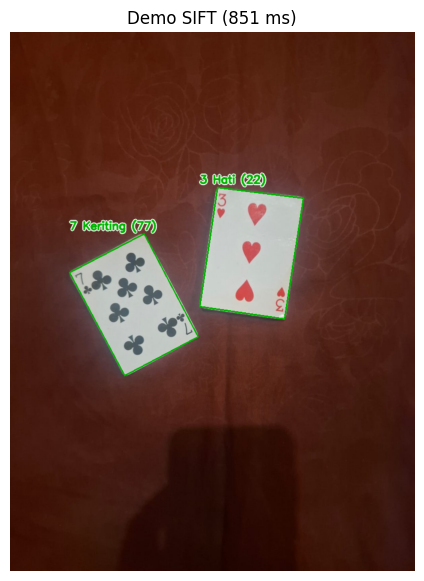

3 Hati: good=22, inlier=9, skor=22
7 Keriting: good=77, inlier=33, skor=77


In [18]:
DEMO_PATH = os.path.join(DATASET_DIR, 'demo', 'demo_01.jpeg')   # foto baru untuk demo
if not os.path.isfile(DEMO_PATH):
    DEMO_PATH = os.path.join(DATASET_DIR, 'sulit', 'sulit_06.jpeg')
    print('Foto demo baru tidak ada, memakai foto uji:', os.path.basename(DEMO_PATH))


def demo(path, method=DETEKTOR_UTAMA):
    if not os.path.isfile(path):
        print(f'Foto tidak ditemukan: {path}')
        return
    asli = baca_citra(path)
    img = resize_maks(asli)
    t0 = time.perf_counter()
    hasil = kenali_gambar(img, method, kandidat=deteksi_kartu(img, asli=asli))
    dt = time.perf_counter() - t0
    out = gambar_hasil(img, hasil)
    plt.figure(figsize=(6, 7))
    plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title(f'Demo {method.upper()} ({1000 * dt:.0f} ms)')
    plt.show()
    for h in hasil:
        print(f"{nama_tampil(h['nama']) if h['diterima'] else 'tidak dikenali'}: good={h['good']}, inlier={h['inlier']}, skor={h['skor']}")
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    cv2.imwrite(os.path.join(OUTPUT_DIR, 'demo_hasil.jpg'), out)


demo(DEMO_PATH)